In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

# Your MiDaS dataset location: already extracted folders, NOT zip files.
dataset_path = "/content/drive/MyDrive/BN5211_Depth_Project"
assert Path(dataset_path).is_dir(), f"Missing: {dataset_path}"
print("Available:", os.listdir(dataset_path))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Available: ['trans_t1_a', 'trans_t2_b', 'results']


In [4]:
import os, shutil
from pathlib import Path

# Preserve the original DAv2 notebook's expected local folder layout.
# Only the data source changes; model and evaluation code stay unchanged.
for name in ["trans_t1_a", "trans_t2_b"]:
    source_root = Path(dataset_path) / name
    assert source_root.is_dir(), f"Missing dataset folder: {source_root}"
    candidates = [source_root, source_root / name]
    source = next((p for p in candidates if list(p.glob("*_color.png"))), None)
    if source is None:
        matches = list(source_root.rglob("*_color.png"))
        assert matches, f"No RGB frames in {source_root}"
        source = matches[0].parent
    destination = Path("/content/C3VD") / name / name
    destination.mkdir(parents=True, exist_ok=True)
    for file in source.iterdir():
        if file.is_file():
            shutil.copy2(file, destination / file.name)
    print(name, "source:", source, "RGB frames:", len(list(destination.glob("*_color.png"))))


trans_t1_a source: /content/drive/MyDrive/BN5211_Depth_Project/trans_t1_a RGB frames: 61
trans_t2_b source: /content/drive/MyDrive/BN5211_Depth_Project/trans_t2_b RGB frames: 103


In [5]:
for name in ["trans_t1_a", "trans_t2_b"]:
    folder = f"/content/C3VD/{name}"

    print(f"\n{name}:")
    print(os.listdir(folder)[:15])


trans_t1_a:
['trans_t1_a']

trans_t2_b:
['trans_t2_b']


In [6]:
import os

for name in ["trans_t1_a", "trans_t2_b"]:
    folder = f"/content/C3VD/{name}/{name}"

    print(f"\n{name}:")
    print(os.listdir(folder)[:20])
    print("Total files:", len(os.listdir(folder)))


trans_t1_a:
['0060_occlusion.png', '0050_occlusion.png', '0012_color.png', '0038_normals.tiff', '0027_normals.tiff', '0054_color.png', '0053_depth.tiff', '0047_color.png', '0030_normals.tiff', '0025_depth.tiff', '0059_color.png', '0011_occlusion.png', '0012_normals.tiff', '0051_flow.tiff', '0031_occlusion.png', '0051_depth.tiff', '0053_flow.tiff', '0002_flow.tiff', 'pose.txt', '0007_flow.tiff']
Total files: 306

trans_t2_b:
['0077_occlusion.png', '0084_flow.tiff', '0071_flow.tiff', '0060_occlusion.png', '0086_flow.tiff', '0050_occlusion.png', '0012_color.png', '0038_normals.tiff', '0027_normals.tiff', '0054_color.png', '0053_depth.tiff', '0047_color.png', '0079_occlusion.png', '0030_normals.tiff', '0025_depth.tiff', '0059_color.png', '0073_occlusion.png', '0011_occlusion.png', '0012_normals.tiff', '0051_flow.tiff']
Total files: 516


RGB shape: (1080, 1350, 3)
Depth shape: (1080, 1350)
Depth datatype: uint16
Depth range: 0 65535


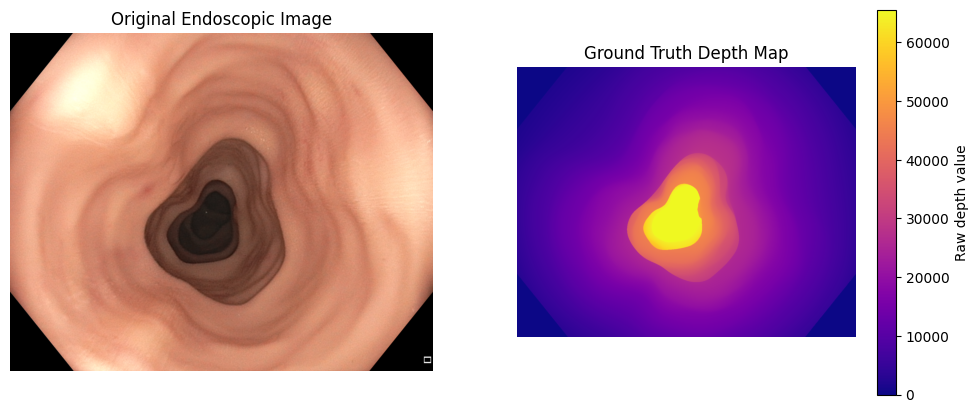

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

folder = "/content/C3VD/trans_t1_a/trans_t1_a"

# Load first RGB image
rgb = cv2.imread(f"{folder}/0001_color.png")
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

# Load corresponding depth map
depth = cv2.imread(
    f"{folder}/0001_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

print("RGB shape:", rgb.shape)
print("Depth shape:", depth.shape)
print("Depth datatype:", depth.dtype)
print("Depth range:", np.min(depth), np.max(depth))

# Display both
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Endoscopic Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth, cmap="plasma")
plt.title("Ground Truth Depth Map")
plt.colorbar(label="Raw depth value")
plt.axis("off")

plt.show()

Minimum valid depth (mm): 2.4429693
Maximum valid depth (mm): 100.0
Mean valid depth (mm): 25.035471


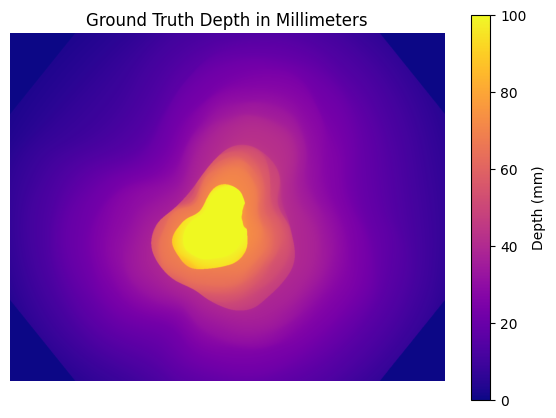

In [8]:
# Convert 16-bit depth to millimeters
depth_mm = depth.astype(np.float32) / 65535.0 * 100.0

# Exclude zero-depth pixels
valid_mask = depth > 0

print("Minimum valid depth (mm):", depth_mm[valid_mask].min())
print("Maximum valid depth (mm):", depth_mm[valid_mask].max())
print("Mean valid depth (mm):", depth_mm[valid_mask].mean())

plt.figure(figsize=(7, 5))
plt.imshow(depth_mm, cmap="plasma", vmin=0, vmax=100)
plt.colorbar(label="Depth (mm)")
plt.title("Ground Truth Depth in Millimeters")
plt.axis("off")
plt.show()

In [9]:
%cd /content

!git clone https://github.com/DepthAnything/Depth-Anything-V2.git

%cd /content/Depth-Anything-V2

/content
Cloning into 'Depth-Anything-V2'...
remote: Enumerating objects: 146, done.
remote: Total 146 (delta 0), reused 0 (delta 0), pack-reused 146 (from 1)
Receiving objects: 100% (146/146), 45.18 MiB | 17.46 MiB/s, done.
Resolving deltas: 100% (45/45), done.
/content/Depth-Anything-V2


In [10]:
!pip install -q -r requirements.txt

In [11]:
import os

print("Current directory:", os.getcwd())
print("Model installed:", os.path.exists("depth_anything_v2/dpt.py"))

Current directory: /content/Depth-Anything-V2
Model installed: True


In [12]:
%cd /content/Depth-Anything-V2

!mkdir -p checkpoints

!wget -q --show-progress \
https://huggingface.co/depth-anything/Depth-Anything-V2-Small/resolve/main/depth_anything_v2_vits.pth \
-O checkpoints/depth_anything_v2_vits.pth

/content/Depth-Anything-V2
checkpoints/depth_a 100%[===================>]  94.62M   136MB/s    in 0.7s    


In [13]:
import os

model_path = "checkpoints/depth_anything_v2_vits.pth"

print("Weights downloaded:", os.path.exists(model_path))
print("File size (MB):", round(os.path.getsize(model_path) / 1e6, 2))

Weights downloaded: True
File size (MB): 99.22


In [14]:
import torch
from depth_anything_v2.dpt import DepthAnythingV2

# Model configuration
model = DepthAnythingV2(
    encoder='vits',
    features=64,
    out_channels=[48, 96, 192, 384]
)

# Load pretrained weights
model.load_state_dict(
    torch.load(
        'checkpoints/depth_anything_v2_vits.pth',
        map_location='cpu',
        weights_only=True
    )
)

# Move model to GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = model.to(device).eval()

print("Model loaded successfully!")
print("Running on:", device)
print("Model: Depth Anything V2 Small")

Model loaded successfully!
Running on: cuda
Model: Depth Anything V2 Small


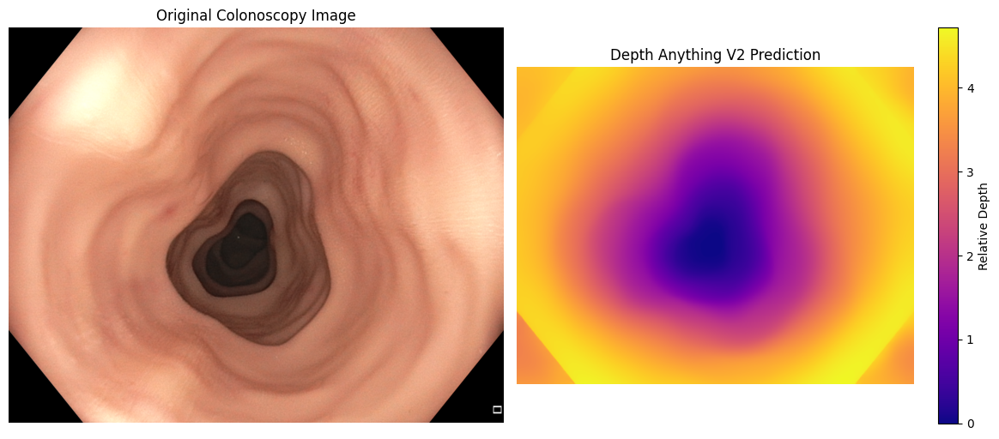

Prediction shape: (1080, 1350)
Minimum prediction: 0.0
Maximum prediction: 4.7171526


In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load C3VD image
image_path = "/content/C3VD/trans_t1_a/trans_t1_a/0001_color.png"

image = cv2.imread(image_path)

# Generate depth prediction
with torch.no_grad():
    predicted_depth = model.infer_image(image, input_size=518)

# Convert image to RGB for display
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display original image and predicted depth
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_depth, cmap="plasma")
plt.title("Depth Anything V2 Prediction")
plt.colorbar(label="Relative Depth")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_depth.shape)
print("Minimum prediction:", predicted_depth.min())
print("Maximum prediction:", predicted_depth.max())

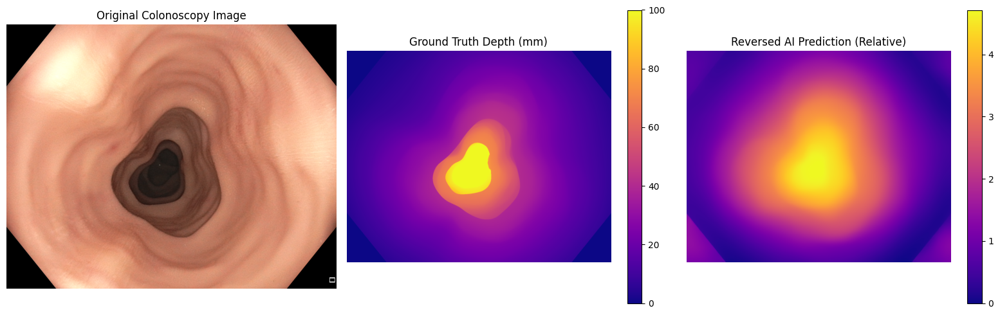

In [16]:
# Reverse relative-depth direction
reversed_depth = predicted_depth.max() - predicted_depth

# Display comparison
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb_image)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(depth_mm, cmap="plasma")
plt.title("Ground Truth Depth (mm)")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(reversed_depth, cmap="plasma")
plt.title("Reversed AI Prediction (Relative)")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

Correlation: 0.9091128552648828


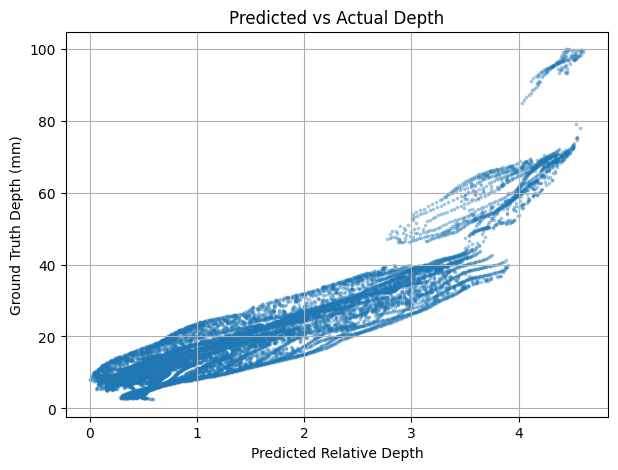

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Select valid ground-truth pixels
valid_mask = (depth > 0) & (depth < 65535)

# Extract corresponding values
gt_values = depth_mm[valid_mask]
pred_values = reversed_depth[valid_mask]

# Calculate correlation
correlation = np.corrcoef(
    gt_values, pred_values
)[0, 1]

print("Correlation:", correlation)

# Plot relationship
plt.figure(figsize=(7, 5))

plt.scatter(
    pred_values[::100],
    gt_values[::100],
    s=3,
    alpha=0.3
)

plt.xlabel("Predicted Relative Depth")
plt.ylabel("Ground Truth Depth (mm)")
plt.title("Predicted vs Actual Depth")
plt.grid(True)
plt.show()

Scale: 13.063408
Offset: 1.3722744


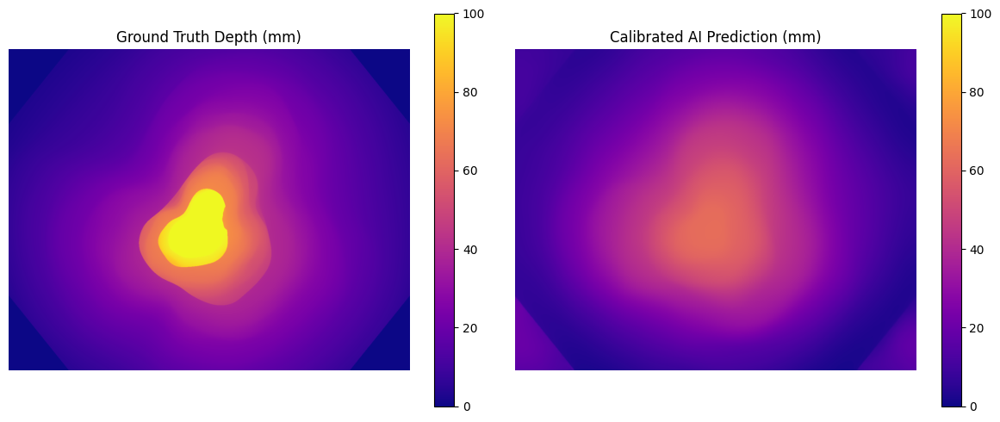

In [20]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

# Use valid pixels from the development image
X = pred_values.reshape(-1, 1)
y = gt_values

# Fit linear calibration
calibrator = LinearRegression()
calibrator.fit(X, y)

# Convert relative depth to millimeters
predicted_depth_mm = calibrator.predict(
    reversed_depth.reshape(-1, 1)
).reshape(reversed_depth.shape)

predicted_depth_mm = np.clip(
    predicted_depth_mm, 0, 100
)

print("Scale:", calibrator.coef_[0])
print("Offset:", calibrator.intercept_)

# Visual comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(depth_mm, cmap="plasma", vmin=0, vmax=100)
plt.title("Ground Truth Depth (mm)")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_depth_mm, cmap="plasma", vmin=0, vmax=100)
plt.title("Calibrated AI Prediction (mm)")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
import os
import cv2
import numpy as np
import torch

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"
output_folder = "/content/C3VD/dev_predictions"

os.makedirs(output_folder, exist_ok=True)

# Find all RGB images
image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

# Run Depth Anything V2 on every image
model.eval()

for i, filename in enumerate(image_files):

    image_path = os.path.join(dev_folder, filename)
    image = cv2.imread(image_path)

    if image is None:
        raise RuntimeError(f"Cannot read {image_path}")

    with torch.inference_mode():
        prediction = model.infer_image(image, input_size=518)

    # Save original model output without calibration
    output_name = filename.replace("_color.png", "_pred.npy")

    np.save(
        os.path.join(output_folder, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(image_files):
        print(f"Processed {i + 1}/{len(image_files)} images")

print("All development predictions saved!")

Total development images: 61
Processed 10/61 images
Processed 20/61 images
Processed 30/61 images
Processed 40/61 images
Processed 50/61 images
Processed 60/61 images
Processed 61/61 images
All development predictions saved!


In [22]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"
output_folder = "/content/C3VD/dev_predictions"

X_all = []
y_all = []

prediction_files = sorted([
    f for f in os.listdir(output_folder)
    if f.endswith("_pred.npy")
])

for filename in prediction_files:

    # Load original AI prediction
    pred = np.load(os.path.join(output_folder, filename))

    # Load corresponding ground-truth depth
    depth_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, depth_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {depth_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Exclude invalid/boundary depth values
    valid = (gt_raw > 0) & (gt_raw < 65535)

    # Use negative prediction because larger model outputs
    # correspond to nearer surfaces in this experiment
    X_all.append((-pred[valid]).reshape(-1, 1))
    y_all.append(gt_mm[valid])

X = np.concatenate(X_all, axis=0)
y = np.concatenate(y_all, axis=0)

# Fit one calibration across all development frames
calibrator = LinearRegression()
calibrator.fit(X, y)

scale = float(calibrator.coef_[0])
offset = float(calibrator.intercept_)

print("Development frames:", len(prediction_files))
print("Total valid pixels:", len(y))
print("Calibration scale:", scale)
print("Calibration offset:", offset)
print("Calibration complete!")

Development frames: 61
Total valid pixels: 80952223
Calibration scale: 13.321044921875
Calibration offset: 64.22636413574219
Calibration complete!


In [23]:
import os
import cv2
import numpy as np

all_absrel = []
all_squared_errors = []
all_delta = []

for filename in prediction_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply fixed calibration
    pred_mm = -scale * pred + offset
    pred_mm = np.clip(pred_mm, 1e-3, 100.0)

    # Valid depth pixels
    valid = (gt_raw > 0) & (gt_raw < 65535)

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # Calculate errors
    all_absrel.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    all_squared_errors.append(
        np.mean((gt - prediction) ** 2)
    )

    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    all_delta.append(
        np.mean(ratio < 1.25)
    )

print("DEVELOPMENT DATASET RESULTS")
print("---------------------------")
print("AbsRel:", np.mean(all_absrel))
print("RMSE (mm):", np.sqrt(np.mean(all_squared_errors)))
print("Delta < 1.25:", np.mean(all_delta))

DEVELOPMENT DATASET RESULTS
---------------------------
AbsRel: 0.31030893
RMSE (mm): 7.2104206
Delta < 1.25: 0.4524115232610192


In [24]:
import numpy as np

# Calculate median ground-truth depth
# using DEVELOPMENT data only
median_depth = float(np.median(y))

print("Constant median depth (mm):", median_depth)
print("Baseline ready!")

Constant median depth (mm): 17.259479522705078
Baseline ready!


In [25]:
import os
import cv2
import numpy as np
import torch

test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"
test_output = "/content/C3VD/test_predictions"

os.makedirs(test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot read {filename}")

    with torch.inference_mode():
        prediction = model.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    np.save(
        os.path.join(test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All test predictions saved!")

Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All test predictions saved!


In [26]:
import os
import cv2
import numpy as np

results = {
    "Baseline": {"absrel": [], "sqerr": [], "delta": []},
    "Depth Anything V2": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in sorted(os.listdir(test_output)):
    if not filename.endswith("_pred.npy"):
        continue

    # Load AI prediction
    pred = np.load(os.path.join(test_output, filename))

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Provisional valid-depth mask
    valid = (gt_raw > 0) & (gt_raw < 65535)

    gt = gt_mm[valid]

    # Model 1: Constant-median baseline
    baseline = np.full_like(gt, median_depth)

    # Model 2: Depth Anything V2
    calibrated = -scale * pred + offset
    calibrated = np.clip(calibrated, 1e-3, 100.0)
    ai = calibrated[valid]

    for name, prediction in [
        ("Baseline", baseline),
        ("Depth Anything V2", ai)
    ]:
        results[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        results[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        results[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("FINAL TEST COMPARISON")
print("-" * 65)
print(f"{'Model':<22} {'AbsRel':<12} {'RMSE (mm)':<12} {'Delta < 1.25'}")

for name, values in results.items():
    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(f"{name:<22} {absrel:<12.4f} {rmse:<12.4f} {delta:.4f}")

FINAL TEST COMPARISON
-----------------------------------------------------------------
Model                  AbsRel       RMSE (mm)    Delta < 1.25
Baseline               0.5499       17.7102      0.2752
Depth Anything V2      0.3323       7.1045       0.4587


In [27]:
import os
import shutil
import json

save_folder = "/content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2"

os.makedirs(save_folder, exist_ok=True)

# Save development and test predictions
shutil.copytree(
    "/content/C3VD/dev_predictions",
    f"{save_folder}/dev_predictions",
    dirs_exist_ok=True
)

shutil.copytree(
    "/content/C3VD/test_predictions",
    f"{save_folder}/test_predictions",
    dirs_exist_ok=True
)

# Save calibration and baseline parameters
parameters = {
    "model": "Depth Anything V2 Small",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(scale),
    "offset": float(offset),
    "median_depth_mm": float(median_depth),
    "input_size": 518
}

with open(f"{save_folder}/parameters.json", "w") as f:
    json.dump(parameters, f, indent=4)

print("All results saved to Google Drive!")
print("Location:", save_folder)

All results saved to Google Drive!
Location: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2


In [28]:
import cv2
import numpy as np

folder = "/content/C3VD/trans_t1_a/trans_t1_a"

gt_raw = cv2.imread(
    f"{folder}/0001_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

total = gt_raw.size

zero_pixels = np.sum(gt_raw == 0)
max_pixels = np.sum(gt_raw == 65535)
other_pixels = np.sum((gt_raw > 0) & (gt_raw < 65535))

print("Depth datatype:", gt_raw.dtype)
print("Total pixels:", total)

print("\nPixel distribution:")
print("Zero pixels:", zero_pixels)
print("65535 pixels:", max_pixels)
print("Other pixels:", other_pixels)

print("\nPercentages:")
print("Zero pixels:", round(zero_pixels / total * 100, 2), "%")
print("65535 pixels:", round(max_pixels / total * 100, 2), "%")
print("Other pixels:", round(other_pixels / total * 100, 2), "%")

print("\nDepth percentiles (raw values):")
print(np.percentile(gt_raw, [0, 1, 25, 50, 75, 99, 100]))

Depth datatype: uint16
Total pixels: 1458000

Pixel distribution:
Zero pixels: 102049
65535 pixels: 28974
Other pixels: 1326977

Percentages:
Zero pixels: 7.0 %
65535 pixels: 1.99 %
Other pixels: 91.01 %

Depth percentiles (raw values):
[    0.     0.  6618. 11887. 19491. 65535. 65535.]


In [29]:
import os
import cv2
import numpy as np

results_new = {
    "Baseline": {"absrel": [], "sqerr": [], "delta": []},
    "Depth Anything V2": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in sorted(os.listdir(test_output)):

    if not filename.endswith("_pred.npy"):
        continue

    pred = np.load(os.path.join(test_output, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Include 65535 (100 mm), exclude zero
    valid = gt_raw > 0

    gt = gt_mm[valid]

    baseline = np.full_like(gt, median_depth)

    calibrated = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    ai = calibrated[valid]

    for name, prediction in [
        ("Baseline", baseline),
        ("Depth Anything V2", ai)
    ]:

        results_new[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        results_new[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        results_new[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("TEST RESULTS INCLUDING 100 mm PIXELS")
print("-" * 65)

for name, values in results_new.items():

    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(
        f"{name}: AbsRel={absrel:.4f}, "
        f"RMSE={rmse:.4f} mm, "
        f"Delta={delta:.4f}"
    )

TEST RESULTS INCLUDING 100 mm PIXELS
-----------------------------------------------------------------
Baseline: AbsRel=0.5559, RMSE=21.3165 mm, Delta=0.2693
Depth Anything V2: AbsRel=0.3334, RMSE=8.9634 mm, Delta=0.4488


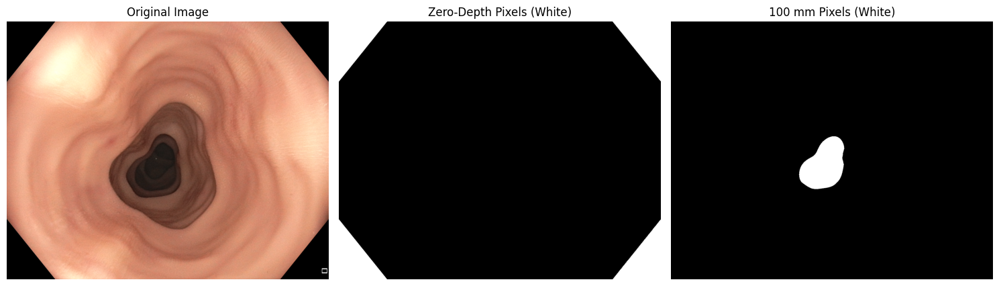

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

folder = "/content/C3VD/trans_t1_a/trans_t1_a"

rgb = cv2.cvtColor(
    cv2.imread(f"{folder}/0001_color.png"),
    cv2.COLOR_BGR2RGB
)

gt_raw = cv2.imread(
    f"{folder}/0001_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

zero_mask = gt_raw == 0
max_mask = gt_raw == 65535

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(zero_mask, cmap="gray")
plt.title("Zero-Depth Pixels (White)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(max_mask, cmap="gray")
plt.title("100 mm Pixels (White)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_all = []
y_all = []

for filename in prediction_files:
    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Final evaluation mask
    valid = gt_raw > 0

    X_all.append((-pred[valid]).reshape(-1, 1))
    y_all.append(gt_mm[valid])

X = np.concatenate(X_all)
y = np.concatenate(y_all)

calibrator = LinearRegression()
calibrator.fit(X, y)

scale = float(calibrator.coef_[0])
offset = float(calibrator.intercept_)
median_depth = float(np.median(y))

print("Updated scale:", scale)
print("Updated offset:", offset)
print("Updated median baseline (mm):", median_depth)
print("Total valid development pixels:", len(y))

Updated scale: 14.802687644958496
Updated offset: 69.5309829711914
Updated median baseline (mm): 17.582971572875977
Total valid development pixels: 82713011


In [32]:
import os
import cv2
import numpy as np

results_final = {
    "Baseline": {"absrel": [], "sqerr": [], "delta": []},
    "Depth Anything V2": {"absrel": [], "sqerr": [], "delta": []}
}

test_files = sorted([
    f for f in os.listdir(test_output)
    if f.endswith("_pred.npy")
])

for filename in test_files:

    # Load model prediction
    pred = np.load(os.path.join(test_output, filename))

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Consistent evaluation mask
    valid = gt_raw > 0
    gt = gt_mm[valid]

    # Constant-median baseline
    baseline = np.full_like(gt, median_depth)

    # Depth Anything V2 calibrated prediction
    calibrated = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )
    ai = calibrated[valid]

    for name, prediction in [
        ("Baseline", baseline),
        ("Depth Anything V2", ai)
    ]:
        results_final[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        results_final[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        results_final[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("UPDATED TEST RESULTS")
print("-" * 65)
print(f"{'Model':<22} {'AbsRel':<12} {'RMSE (mm)':<12} {'Delta < 1.25'}")

for name, values in results_final.items():
    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(f"{name:<22} {absrel:<12.4f} {rmse:<12.4f} {delta:.4f}")

UPDATED TEST RESULTS
-----------------------------------------------------------------
Model                  AbsRel       RMSE (mm)    Delta < 1.25
Baseline               0.5655       21.2086      0.2704
Depth Anything V2      0.3700       8.7136       0.4162


In [33]:
import os
import json
import pandas as pd

save_folder = "/content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2"
os.makedirs(save_folder, exist_ok=True)

# Save updated calibration
parameters = {
    "model": "Depth Anything V2 Small",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(scale),
    "offset": float(offset),
    "median_depth_mm": float(median_depth),
    "input_size": 518,
    "valid_depth_mask": "gt_raw > 0",
    "depth_range_mm": [0, 100]
}

with open(f"{save_folder}/parameters.json", "w") as f:
    json.dump(parameters, f, indent=4)

# Save evaluation results
rows = []

for name, values in results_final.items():
    rows.append({
        "Model": name,
        "AbsRel": float(np.mean(values["absrel"])),
        "RMSE_mm": float(np.sqrt(np.mean(values["sqerr"]))),
        "Delta_1.25": float(np.mean(values["delta"]))
    })

df = pd.DataFrame(rows)
df.to_csv(f"{save_folder}/test_results.csv", index=False)

print("Updated parameters and results saved!")
print(df.to_string(index=False))

Updated parameters and results saved!
            Model   AbsRel   RMSE_mm  Delta_1.25
         Baseline 0.565481 21.208551    0.270393
Depth Anything V2 0.370023  8.713642    0.416236


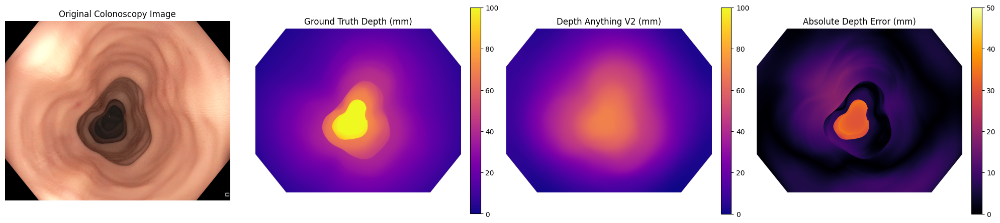

Figure saved to: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/depth_comparison.png
Mean Absolute Error (mm): 6.204653


In [36]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use a development image for visualization
frame = "0001"

folder = "/content/C3VD/trans_t1_a/trans_t1_a"
pred_folder = "/content/C3VD/dev_predictions"

# Load original image
rgb = cv2.imread(f"{folder}/{frame}_color.png")
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

# Load ground truth
gt_raw = cv2.imread(
    f"{folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

# Load saved model prediction
pred = np.load(f"{pred_folder}/{frame}_pred.npy")

# Apply development-set calibration
pred_mm = np.clip(
    -scale * pred + offset,
    1e-3,
    100.0
)

# Valid pixels
valid = gt_raw > 0

# Absolute depth error
error = np.abs(gt_mm - pred_mm)
error[~valid] = np.nan

# Hide invalid pixels in depth maps
gt_display = np.where(valid, gt_mm, np.nan)
pred_display = np.where(valid, pred_mm, np.nan)

# Create comparison figure
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(rgb)
axes[0].set_title("Original Colonoscopy Image")

im1 = axes[1].imshow(
    gt_display, cmap="plasma", vmin=0, vmax=100
)
axes[1].set_title("Ground Truth Depth (mm)")

im2 = axes[2].imshow(
    pred_display, cmap="plasma", vmin=0, vmax=100
)
axes[2].set_title("Depth Anything V2 (mm)")

im3 = axes[3].imshow(
    error, cmap="inferno", vmin=0, vmax=50
)
axes[3].set_title("Absolute Depth Error (mm)")

for ax in axes:
    ax.axis("off")

fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()

# CORRECTED: Save to your Google Drive project folder
save_folder = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/"
    "DepthAnythingV2"
)

os.makedirs(save_folder, exist_ok=True)

save_path = os.path.join(
    save_folder,
    "depth_comparison.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", save_path)
print("Mean Absolute Error (mm):", np.nanmean(error))


0–20 mm: MAE = 4.828 mm, Pixels = 47315777
20–40 mm: MAE = 7.096 mm, Pixels = 21834912
40–60 mm: MAE = 5.265 mm, Pixels = 7681999
60–100 mm: MAE = 19.431 mm, Pixels = 5880323


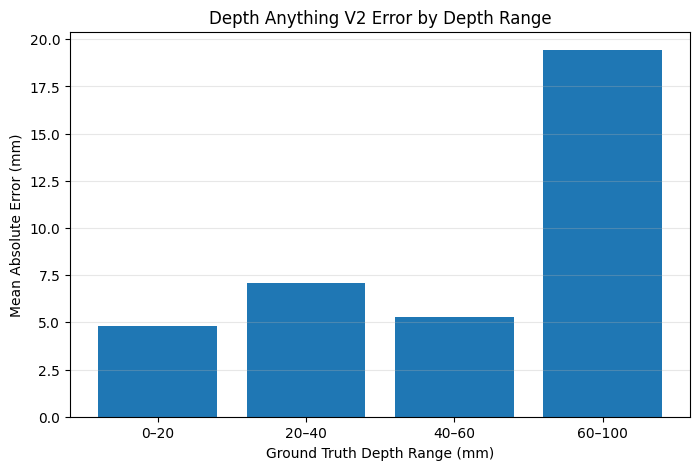

In [37]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

depth_ranges = [(0, 20), (20, 40), (40, 60), (60, 100)]

error_sums = np.zeros(4, dtype=np.float64)
pixel_counts = np.zeros(4, dtype=np.int64)

for filename in prediction_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    valid = gt_raw > 0
    error = np.abs(gt_mm - pred_mm)

    for i, (low, high) in enumerate(depth_ranges):

        if high == 100:
            mask = valid & (gt_mm >= low) & (gt_mm <= high)
        else:
            mask = valid & (gt_mm >= low) & (gt_mm < high)

        error_sums[i] += np.sum(error[mask], dtype=np.float64)
        pixel_counts[i] += np.count_nonzero(mask)

mae_by_range = error_sums / np.maximum(pixel_counts, 1)

labels = ["0–20", "20–40", "40–60", "60–100"]

for label, mae, count in zip(labels, mae_by_range, pixel_counts):
    print(f"{label} mm: MAE = {mae:.3f} mm, Pixels = {count}")

plt.figure(figsize=(8, 5))
plt.bar(labels, mae_by_range)
plt.xlabel("Ground Truth Depth Range (mm)")
plt.ylabel("Mean Absolute Error (mm)")
plt.title("Depth Anything V2 Error by Depth Range")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [38]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# X and y were created from all development frames in Step 27
# X = negative raw model predictions
# y = ground-truth depth in millimeters

# Use a sample to reduce computation
rng = np.random.default_rng(42)
sample_size = min(500000, len(y))

indices = rng.choice(
    len(y),
    size=sample_size,
    replace=False
)

X_sample = X[indices]
y_sample = y[indices]

# Create second-degree polynomial features
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_poly = poly.fit_transform(X_sample)

# Train nonlinear calibration
poly_model = LinearRegression()
poly_model.fit(X_poly, y_sample)

print("Polynomial coefficients:", poly_model.coef_)
print("Intercept:", poly_model.intercept_)
print("Polynomial calibration trained successfully!")

Polynomial coefficients: [ 0.44736296 -2.4325354 ]
Intercept: 52.119026
Polynomial calibration trained successfully!


In [39]:
import os
import cv2
import numpy as np

comparison = {
    "Linear": {"absrel": [], "sqerr": [], "delta": []},
    "Polynomial": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in prediction_files:

    # Load saved prediction
    pred = np.load(os.path.join(output_folder, filename))

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    # Original linear calibration
    linear_depth = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    # New polynomial calibration
    # Coefficients correspond to P and P^2, where P = -pred
    p = -pred
    a, b = poly_model.coef_

    polynomial_depth = np.clip(
        a * p + b * p**2 + poly_model.intercept_,
        1e-3, 100.0
    )

    gt = gt_mm[valid]

    for name, prediction_map in [
        ("Linear", linear_depth),
        ("Polynomial", polynomial_depth)
    ]:
        prediction = prediction_map[valid]

        comparison[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        comparison[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        comparison[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("DEVELOPMENT DATASET COMPARISON")
print("-" * 65)

for name, values in comparison.items():
    print(
        f"{name}: "
        f"AbsRel={np.mean(values['absrel']):.4f}, "
        f"RMSE={np.sqrt(np.mean(values['sqerr'])):.4f} mm, "
        f"Delta={np.mean(values['delta']):.4f}"
    )

DEVELOPMENT DATASET COMPARISON
-----------------------------------------------------------------
Linear: AbsRel=0.3425, RMSE=8.7923 mm, Delta=0.4043
Polynomial: AbsRel=0.4304, RMSE=11.7330 mm, Delta=0.3227


Filtering completed successfully!
Original MAE: 6.204653
Refined MAE: 6.204474


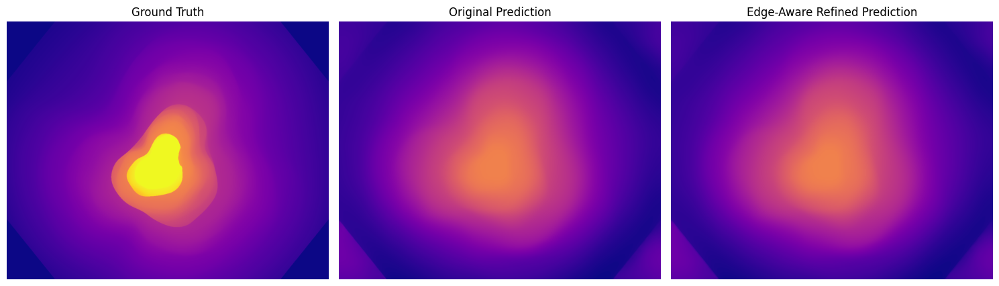

In [40]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use development image 0001
frame = "0001"

folder = "/content/C3VD/trans_t1_a/trans_t1_a"
pred_folder = "/content/C3VD/dev_predictions"

rgb = cv2.imread(f"{folder}/{frame}_color.png")

pred = np.load(f"{pred_folder}/{frame}_pred.npy")

# Apply original linear calibration
linear_depth = np.clip(
    -scale * pred + offset,
    1e-3, 100.0
).astype(np.float32)

# Install guided filtering support if necessary
!pip -q install opencv-contrib-python-headless

# Convert guide image to float32
guide = cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY)
guide = guide.astype(np.float32)

# Apply joint bilateral filtering
refined_depth = cv2.ximgproc.jointBilateralFilter(
    joint=guide,
    src=linear_depth,
    d=9,
    sigmaColor=25,
    sigmaSpace=5
)

print("Filtering completed successfully!")

# Load ground truth
gt_raw = cv2.imread(
    f"{folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
valid = gt_raw > 0

# Compare mean absolute errors
original_mae = np.mean(
    np.abs(gt_mm[valid] - linear_depth[valid])
)

refined_mae = np.mean(
    np.abs(gt_mm[valid] - refined_depth[valid])
)

print("Original MAE:", original_mae)
print("Refined MAE:", refined_mae)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(gt_mm, cmap="plasma", vmin=0, vmax=100)
axes[0].set_title("Ground Truth")

axes[1].imshow(linear_depth, cmap="plasma", vmin=0, vmax=100)
axes[1].set_title("Original Prediction")

axes[2].imshow(refined_depth, cmap="plasma", vmin=0, vmax=100)
axes[2].set_title("Edge-Aware Refined Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

EDGE-AWARE FILTER COMPARISON
--------------------------------------------------
Setting              MAE (mm)       
d=9, sc=25, ss=5: 6.204474
d=15, sc=50, ss=10: 6.204211
d=25, sc=75, ss=15: 6.203033

Original MAE: 6.204653


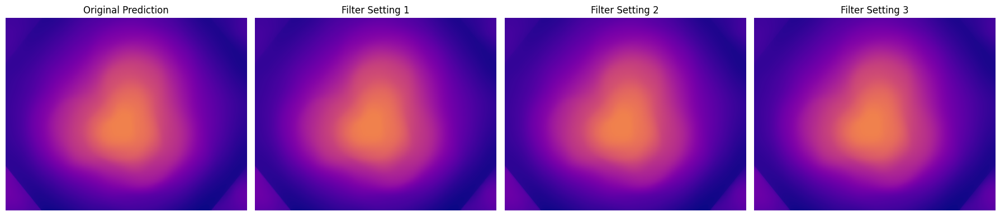

In [41]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Different filtering strengths
settings = [
    (9, 25, 5),
    (15, 50, 10),
    (25, 75, 15)
]

print("EDGE-AWARE FILTER COMPARISON")
print("-" * 50)
print(f"{'Setting':<20} {'MAE (mm)':<15}")

filtered_maps = []

for d, sigma_color, sigma_space in settings:

    refined = cv2.ximgproc.jointBilateralFilter(
        joint=guide,
        src=linear_depth,
        d=d,
        sigmaColor=sigma_color,
        sigmaSpace=sigma_space
    )

    mae = np.mean(
        np.abs(gt_mm[valid] - refined[valid])
    )

    filtered_maps.append(refined)

    print(
        f"d={d}, sc={sigma_color}, ss={sigma_space}: "
        f"{mae:.6f}"
    )

print(f"\nOriginal MAE: {original_mae:.6f}")

# Visualize
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(linear_depth, cmap="plasma", vmin=0, vmax=100)
axes[0].set_title("Original Prediction")

for i, refined in enumerate(filtered_maps):
    axes[i+1].imshow(
        refined, cmap="plasma", vmin=0, vmax=100
    )
    axes[i+1].set_title(f"Filter Setting {i+1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

MEAN SIGNED DEPTH ERROR
------------------------
0–20 mm: 0.123 mm
20–40 mm: -4.550 mm
40–60 mm: -2.981 mm
60–100 mm: 19.417 mm


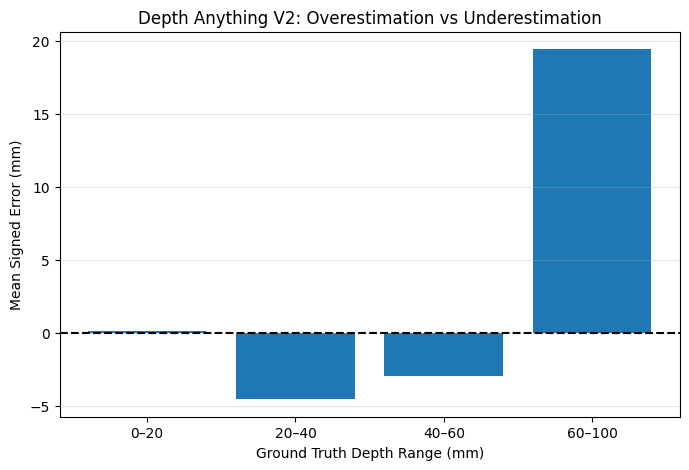

In [42]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

depth_ranges = [(0, 20), (20, 40), (40, 60), (60, 100)]

error_sums = np.zeros(4)
pixel_counts = np.zeros(4)

for filename in prediction_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    valid = gt_raw > 0

    # Signed error: positive means underestimation
    signed_error = gt_mm - pred_mm

    for i, (low, high) in enumerate(depth_ranges):

        if high == 100:
            mask = valid & (gt_mm >= low) & (gt_mm <= high)
        else:
            mask = valid & (gt_mm >= low) & (gt_mm < high)

        error_sums[i] += np.sum(
            signed_error[mask], dtype=np.float64
        )

        pixel_counts[i] += np.count_nonzero(mask)

mean_signed_errors = error_sums / pixel_counts

labels = ["0–20", "20–40", "40–60", "60–100"]

print("MEAN SIGNED DEPTH ERROR")
print("------------------------")

for label, error in zip(labels, mean_signed_errors):
    print(f"{label} mm: {error:.3f} mm")

plt.figure(figsize=(8, 5))
plt.bar(labels, mean_signed_errors)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Ground Truth Depth Range (mm)")
plt.ylabel("Mean Signed Error (mm)")
plt.title("Depth Anything V2: Overestimation vs Underestimation")
plt.grid(axis="y", alpha=0.3)
plt.show()

ERROR BY PREDICTED DEPTH
---------------------------------------------
0–20 mm: Signed Error = 1.852 mm, Pixels = 42761235
20–40 mm: Signed Error = -5.170 mm, Pixels = 21284495
40–60 mm: Signed Error = -5.013 mm, Pixels = 13919401
60–80 mm: Signed Error = 20.718 mm, Pixels = 4747880
80–100 mm: Signed Error = nan mm, Pixels = 0


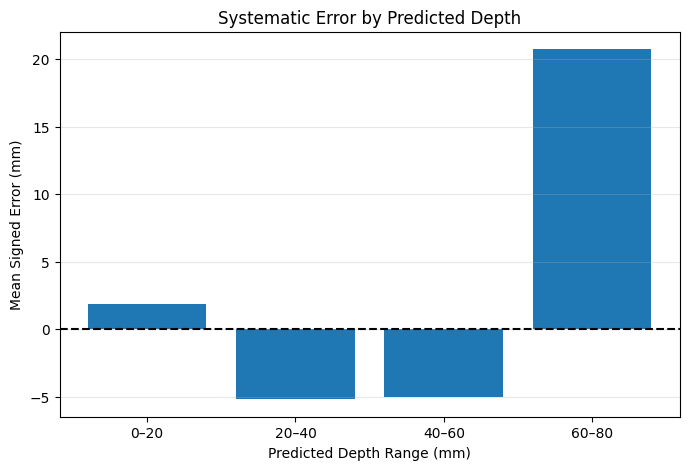

In [43]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Predicted-depth intervals
bins = [0, 20, 40, 60, 80, 100]

error_sums = np.zeros(5, dtype=np.float64)
pixel_counts = np.zeros(5, dtype=np.int64)

for filename in prediction_files:

    pred = np.load(
        os.path.join(output_folder, filename)
    )

    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    valid = gt_raw > 0

    signed_error = gt_mm - pred_mm

    for i in range(len(bins) - 1):

        low = bins[i]
        high = bins[i + 1]

        if high == 100:
            mask = valid & (pred_mm >= low) & (pred_mm <= high)
        else:
            mask = valid & (pred_mm >= low) & (pred_mm < high)

        error_sums[i] += np.sum(
            signed_error[mask],
            dtype=np.float64
        )

        pixel_counts[i] += np.count_nonzero(mask)

mean_errors = np.divide(
    error_sums,
    pixel_counts,
    out=np.full(5, np.nan),
    where=pixel_counts > 0
)

labels = ["0–20", "20–40", "40–60", "60–80", "80–100"]

print("ERROR BY PREDICTED DEPTH")
print("-" * 45)

for label, error, count in zip(
    labels, mean_errors, pixel_counts
):
    print(
        f"{label} mm: "
        f"Signed Error = {error:.3f} mm, "
        f"Pixels = {count}"
    )

plt.figure(figsize=(8, 5))
plt.bar(labels, mean_errors)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted Depth Range (mm)")
plt.ylabel("Mean Signed Error (mm)")
plt.title("Systematic Error by Predicted Depth")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [44]:
import os
import numpy as np

# Existing saved predictions from trans_t1_a
all_files = sorted([
    f for f in os.listdir(output_folder)
    if f.endswith("_pred.npy")
])

train_files = all_files[:45]
val_files = all_files[45:]

print("Training frames:", len(train_files))
print("Validation frames:", len(val_files))

print("\nTraining:")
print(train_files[0], "to", train_files[-1])

print("\nValidation:")
print(val_files[0], "to", val_files[-1])

Training frames: 45
Validation frames: 16

Training:
0000_pred.npy to 0044_pred.npy

Validation:
0045_pred.npy to 0060_pred.npy


In [45]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_train = []
y_train = []

for filename in train_files:

    # Load saved Depth Anything V2 prediction
    pred = np.load(
        os.path.join(output_folder, filename)
    )

    # Load corresponding ground-truth depth
    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    # Convert depth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Exclude zero-depth background
    valid = gt_raw > 0

    # Use negative raw prediction
    X_train.append((-pred[valid]).reshape(-1, 1))
    y_train.append(gt_mm[valid])

# Combine training data
X_train = np.concatenate(X_train)
y_train = np.concatenate(y_train)

# Train linear calibration
linear_train_model = LinearRegression()
linear_train_model.fit(X_train, y_train)

train_scale = float(linear_train_model.coef_[0])
train_offset = float(linear_train_model.intercept_)

print("TRAINING-ONLY LINEAR CALIBRATION")
print("--------------------------------")
print("Training frames:", len(train_files))
print("Training pixels:", len(y_train))
print("Scale:", train_scale)
print("Offset:", train_offset)
print("Training completed!")

TRAINING-ONLY LINEAR CALIBRATION
--------------------------------
Training frames: 45
Training pixels: 61017795
Scale: 14.583353042602539
Offset: 68.20346069335938
Training completed!


In [46]:
import numpy as np

# Predicted-depth intervals in millimeters
bins = np.array([0, 20, 40, 60, 80, 100])

# Apply training-only linear calibration
train_pred_mm = np.clip(
    train_scale * X_train[:, 0] + train_offset,
    1e-3,
    100.0
)

# Calculate signed errors
train_errors = y_train - train_pred_mm

# Learn correction for each predicted-depth range
corrections = []
counts = []

for i in range(len(bins) - 1):

    low = bins[i]
    high = bins[i + 1]

    if high == 100:
        mask = (train_pred_mm >= low) & (train_pred_mm <= high)
    else:
        mask = (train_pred_mm >= low) & (train_pred_mm < high)

    count = np.count_nonzero(mask)

    if count > 0:
        correction = float(np.mean(train_errors[mask]))
    else:
        correction = 0.0

    corrections.append(correction)
    counts.append(count)

print("LEARNED DEPTH CORRECTIONS")
print("-" * 55)

for i in range(len(corrections)):
    print(
        f"{bins[i]}-{bins[i+1]} mm: "
        f"Correction = {corrections[i]:.3f} mm, "
        f"Pixels = {counts[i]}"
    )

print("\nBias correction model trained successfully!")

LEARNED DEPTH CORRECTIONS
-------------------------------------------------------
0-20 mm: Correction = 1.857 mm, Pixels = 30700131
20-40 mm: Correction = -5.211 mm, Pixels = 16355948
40-60 mm: Correction = -4.206 mm, Pixels = 10902135
60-80 mm: Correction = 23.373 mm, Pixels = 3059581
80-100 mm: Correction = 0.000 mm, Pixels = 0

Bias correction model trained successfully!


In [47]:
import os
import cv2
import numpy as np

validation_results = {
    "Linear": {"absrel": [], "sqerr": [], "delta": []},
    "Bias Corrected": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in val_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    # Linear calibration trained on 45 frames
    linear_depth = np.clip(
        -train_scale * pred + train_offset,
        1e-3, 100.0
    )

    # Apply learned depth-dependent correction
    corrected_depth = linear_depth.copy()

    for i in range(len(bins) - 1):
        low, high = bins[i], bins[i + 1]

        if high == 100:
            mask = (linear_depth >= low) & (linear_depth <= high)
        else:
            mask = (linear_depth >= low) & (linear_depth < high)

        corrected_depth[mask] += corrections[i]

    corrected_depth = np.clip(
        corrected_depth, 1e-3, 100.0
    )

    gt = gt_mm[valid]

    for name, depth_map in [
        ("Linear", linear_depth),
        ("Bias Corrected", corrected_depth)
    ]:
        prediction = depth_map[valid]

        validation_results[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        validation_results[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        validation_results[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("VALIDATION RESULTS — 16 FRAMES")
print("-" * 65)

for name, values in validation_results.items():
    print(
        f"{name}: "
        f"AbsRel={np.mean(values['absrel']):.4f}, "
        f"RMSE={np.sqrt(np.mean(values['sqerr'])):.4f} mm, "
        f"Delta={np.mean(values['delta']):.4f}"
    )

VALIDATION RESULTS — 16 FRAMES
-----------------------------------------------------------------
Linear: AbsRel=0.3128, RMSE=8.4090 mm, Delta=0.4395
Bias Corrected: AbsRel=0.2686, RMSE=6.1306 mm, Delta=0.5137


Original MAE: 5.7090025
Corrected MAE: 4.7585278


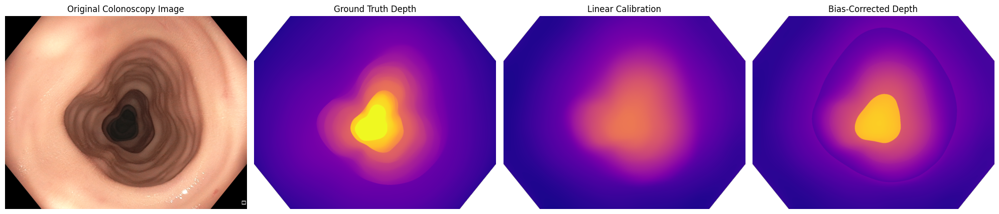

In [48]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# First validation frame
frame = "0045"

folder = "/content/C3VD/trans_t1_a/trans_t1_a"
pred_folder = "/content/C3VD/dev_predictions"

rgb = cv2.imread(f"{folder}/{frame}_color.png")
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

gt_raw = cv2.imread(
    f"{folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
valid = gt_raw > 0

pred = np.load(f"{pred_folder}/{frame}_pred.npy")

# Original linear prediction
linear_depth = np.clip(
    -train_scale * pred + train_offset,
    1e-3, 100.0
)

# Apply bias correction
corrected_depth = linear_depth.copy()

for i in range(len(bins) - 1):
    low, high = bins[i], bins[i + 1]

    if high == 100:
        mask = (linear_depth >= low) & (linear_depth <= high)
    else:
        mask = (linear_depth >= low) & (linear_depth < high)

    corrected_depth[mask] += corrections[i]

corrected_depth = np.clip(corrected_depth, 1e-3, 100.0)

# Calculate absolute errors
linear_error = np.abs(gt_mm - linear_depth)
corrected_error = np.abs(gt_mm - corrected_depth)

print("Original MAE:", np.mean(linear_error[valid]))
print("Corrected MAE:", np.mean(corrected_error[valid]))

# Display results
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

images = [
    rgb,
    np.where(valid, gt_mm, np.nan),
    np.where(valid, linear_depth, np.nan),
    np.where(valid, corrected_depth, np.nan)
]

titles = [
    "Original Colonoscopy Image",
    "Ground Truth Depth",
    "Linear Calibration",
    "Bias-Corrected Depth"
]

for i, ax in enumerate(axes):
    if i == 0:
        ax.imshow(images[i])
    else:
        ax.imshow(images[i], cmap="plasma", vmin=0, vmax=100)

    ax.set_title(titles[i])
    ax.axis("off")

plt.tight_layout()
plt.show()

Original MAE: 5.7090025
Piecewise corrected MAE: 4.7585278
Smooth corrected MAE: 4.49686470979312


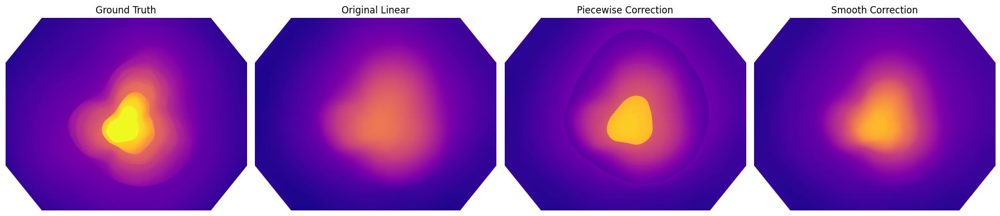

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# Midpoints of the trained depth intervals
bin_centers = np.array([10, 30, 50, 70], dtype=np.float32)

# Corrections learned from 45 training frames
bin_corrections = np.array(corrections[:4], dtype=np.float32)

# Interpolate corrections smoothly
smooth_correction = np.interp(
    linear_depth,
    bin_centers,
    bin_corrections
)

# Apply correction
smooth_depth = np.clip(
    linear_depth + smooth_correction,
    1e-3,
    100.0
)

# Calculate MAE
smooth_mae = np.mean(
    np.abs(gt_mm[valid] - smooth_depth[valid])
)

print("Original MAE:", np.mean(
    np.abs(gt_mm[valid] - linear_depth[valid])
))

print("Piecewise corrected MAE:", np.mean(
    np.abs(gt_mm[valid] - corrected_depth[valid])
))

print("Smooth corrected MAE:", smooth_mae)

# Visualize
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

maps = [
    gt_mm,
    linear_depth,
    corrected_depth,
    smooth_depth
]

titles = [
    "Ground Truth",
    "Original Linear",
    "Piecewise Correction",
    "Smooth Correction"
]

for ax, depth_map, title in zip(axes, maps, titles):
    ax.imshow(
        np.where(valid, depth_map, np.nan),
        cmap="plasma",
        vmin=0,
        vmax=100
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [50]:
import os
import cv2
import numpy as np

methods = ["Linear", "Piecewise", "Smooth"]

results_val = {
    name: {"absrel": [], "sqerr": [], "delta": [], "mae": []}
    for name in methods
}

bin_centers = np.array([10, 30, 50, 70], dtype=np.float32)
bin_corrections = np.array(corrections[:4], dtype=np.float32)

for filename in val_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    # Original linear calibration
    linear = np.clip(
        -train_scale * pred + train_offset,
        1e-3, 100.0
    )

    # Piecewise correction
    piecewise = linear.copy()

    for i in range(len(bins) - 1):
        low, high = bins[i], bins[i + 1]

        if high == 100:
            mask = (linear >= low) & (linear <= high)
        else:
            mask = (linear >= low) & (linear < high)

        piecewise[mask] += corrections[i]

    piecewise = np.clip(piecewise, 1e-3, 100.0)

    # Smooth correction
    smooth = np.clip(
        linear + np.interp(
            linear, bin_centers, bin_corrections
        ),
        1e-3, 100.0
    )

    gt = gt_mm[valid]

    for name, depth_map in [
        ("Linear", linear),
        ("Piecewise", piecewise),
        ("Smooth", smooth)
    ]:
        prediction = depth_map[valid]

        results_val[name]["mae"].append(
            np.mean(np.abs(gt - prediction))
        )

        results_val[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        results_val[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        results_val[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("VALIDATION RESULTS — ALL 16 FRAMES")
print("-" * 75)

for name, values in results_val.items():

    mae = np.mean(values["mae"])
    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(
        f"{name:<12} "
        f"MAE={mae:.4f} mm | "
        f"AbsRel={absrel:.4f} | "
        f"RMSE={rmse:.4f} mm | "
        f"Delta={delta:.4f}"
    )

VALIDATION RESULTS — ALL 16 FRAMES
---------------------------------------------------------------------------
Linear       MAE=5.9373 mm | AbsRel=0.3128 | RMSE=8.4090 mm | Delta=0.4395
Piecewise    MAE=4.6796 mm | AbsRel=0.2686 | RMSE=6.1306 mm | Delta=0.5137
Smooth       MAE=4.4756 mm | AbsRel=0.2507 | RMSE=5.9381 mm | Delta=0.5343


In [51]:
import os
import json
import numpy as np
import pandas as pd

save_folder = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2"
)

os.makedirs(save_folder, exist_ok=True)

# Save the correction model
improvement_parameters = {
    "method": "Smooth Depth-Dependent Bias Correction",
    "training_frames": "0000-0044",
    "validation_frames": "0045-0060",
    "train_scale": float(train_scale),
    "train_offset": float(train_offset),
    "bin_centers_mm": [10, 30, 50, 70],
    "bin_corrections_mm": [
        float(v) for v in corrections[:4]
    ],
    "valid_mask": "gt_raw > 0",
    "interpolation": "numpy.interp"
}

with open(
    f"{save_folder}/smooth_correction_parameters.json", "w"
) as f:
    json.dump(improvement_parameters, f, indent=4)

# Save validation results
rows = []

for name, values in results_val.items():
    rows.append({
        "Method": name,
        "MAE_mm": float(np.mean(values["mae"])),
        "AbsRel": float(np.mean(values["absrel"])),
        "RMSE_mm": float(np.sqrt(np.mean(values["sqerr"]))),
        "Delta_1.25": float(np.mean(values["delta"]))
    })

df = pd.DataFrame(rows)

df.to_csv(
    f"{save_folder}/validation_comparison.csv",
    index=False
)

print("Improvement parameters saved successfully!")
print("Validation results saved successfully!")
print(df.to_string(index=False))

Improvement parameters saved successfully!
Validation results saved successfully!
   Method   MAE_mm   AbsRel  RMSE_mm  Delta_1.25
   Linear 5.937329 0.312809 8.409050    0.439460
Piecewise 4.679622 0.268627 6.130557    0.513721
   Smooth 4.475567 0.250692 5.938050    0.534280


In [52]:
import os
import cv2
import numpy as np

# Fixed depth intervals selected during validation
bins = np.array([0, 20, 40, 60, 80, 100])
bin_centers = np.array([10, 30, 50, 70])

error_sums = np.zeros(5, dtype=np.float64)
pixel_counts = np.zeros(5, dtype=np.int64)

for filename in prediction_files:

    # Load Depth Anything V2 prediction
    pred = np.load(
        os.path.join(output_folder, filename)
    )

    # Load ground-truth depth
    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Use final 61-frame linear calibration
    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    valid = gt_raw > 0

    # Positive error = depth underestimation
    signed_error = gt_mm - pred_mm

    for i in range(len(bins) - 1):

        low = bins[i]
        high = bins[i + 1]

        if high == 100:
            mask = valid & (pred_mm >= low) & (pred_mm <= high)
        else:
            mask = valid & (pred_mm >= low) & (pred_mm < high)

        error_sums[i] += np.sum(
            signed_error[mask],
            dtype=np.float64
        )

        pixel_counts[i] += np.count_nonzero(mask)

final_corrections = np.divide(
    error_sums,
    pixel_counts,
    out=np.zeros(5, dtype=np.float64),
    where=pixel_counts > 0
)

print("FINAL SMOOTH CORRECTION PARAMETERS")
print("-" * 55)

for i in range(5):
    print(
        f"{bins[i]}-{bins[i+1]} mm: "
        f"Correction = {final_corrections[i]:.3f} mm, "
        f"Pixels = {pixel_counts[i]}"
    )

print("\nFinal correction model ready!")

FINAL SMOOTH CORRECTION PARAMETERS
-------------------------------------------------------
0-20 mm: Correction = 1.852 mm, Pixels = 42761235
20-40 mm: Correction = -5.170 mm, Pixels = 21284495
40-60 mm: Correction = -5.013 mm, Pixels = 13919401
60-80 mm: Correction = 20.718 mm, Pixels = 4747880
80-100 mm: Correction = 0.000 mm, Pixels = 0

Final correction model ready!


In [53]:
import os
import cv2
import numpy as np

methods = [
    "Constant Median",
    "Depth Anything V2",
    "Improved Depth Anything V2"
]

test_results = {
    name: {"mae": [], "absrel": [], "sqerr": [], "delta": []}
    for name in methods
}

# Fixed correction parameters learned from development data
centers = np.array([10, 30, 50, 70])
correction_values = final_corrections[:4]

for filename in sorted(os.listdir(test_output)):

    if not filename.endswith("_pred.npy"):
        continue

    # Load saved AI prediction
    pred = np.load(
        os.path.join(test_output, filename)
    )

    # Load ground-truth depth
    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Missing: {gt_filename}")

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Evaluation mask
    valid = gt_raw > 0
    gt = gt_mm[valid]

    # Model 1: Constant median baseline
    baseline = np.full_like(gt_mm, median_depth)

    # Model 2: Original linear calibration
    linear = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    # Model 3: Smooth depth-dependent correction
    correction = np.interp(
        linear, centers, correction_values
    )

    improved = np.clip(
        linear + correction,
        1e-3, 100.0
    )

    for name, depth_map in [
        ("Constant Median", baseline),
        ("Depth Anything V2", linear),
        ("Improved Depth Anything V2", improved)
    ]:

        prediction = depth_map[valid]

        test_results[name]["mae"].append(
            np.mean(np.abs(gt - prediction))
        )

        test_results[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        test_results[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        test_results[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("FINAL TEST RESULTS — 103 FRAMES")
print("-" * 85)

for name, values in test_results.items():

    mae = np.mean(values["mae"])
    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(
        f"{name:<28} "
        f"MAE={mae:.4f} | "
        f"AbsRel={absrel:.4f} | "
        f"RMSE={rmse:.4f} mm | "
        f"Delta={delta:.4f}"
    )

FINAL TEST RESULTS — 103 FRAMES
-------------------------------------------------------------------------------------
Constant Median              MAE=12.9760 | AbsRel=0.5655 | RMSE=21.2086 mm | Delta=0.2704
Depth Anything V2            MAE=6.4007 | AbsRel=0.3700 | RMSE=8.7136 mm | Delta=0.4162
Improved Depth Anything V2   MAE=4.6530 | AbsRel=0.2825 | RMSE=5.8733 mm | Delta=0.5444


In [54]:
import os
import json
import numpy as np
import pandas as pd

save_folder = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2"
)

os.makedirs(save_folder, exist_ok=True)

# Save final correction parameters
final_parameters = {
    "model": "Depth Anything V2 Small",
    "improvement": "Smooth Depth-Dependent Bias Correction",
    "development_dataset": "trans_t1_a",
    "test_dataset": "trans_t2_b",
    "scale": float(scale),
    "offset": float(offset),
    "median_depth_mm": float(median_depth),
    "bin_centers_mm": [10, 30, 50, 70],
    "correction_values_mm": [
        float(v) for v in final_corrections[:4]
    ],
    "evaluation_mask": "gt_raw > 0",
    "depth_range_mm": [0, 100],
    "input_size": 518
}

with open(
    f"{save_folder}/final_model_parameters.json", "w"
) as f:
    json.dump(final_parameters, f, indent=4)

# Save final comparison
rows = []

for name, values in test_results.items():
    rows.append({
        "Method": name,
        "MAE_mm": float(np.mean(values["mae"])),
        "AbsRel": float(np.mean(values["absrel"])),
        "RMSE_mm": float(np.sqrt(np.mean(values["sqerr"]))),
        "Delta_1.25": float(np.mean(values["delta"]))
    })

df_final = pd.DataFrame(rows)

df_final.to_csv(
    f"{save_folder}/final_test_comparison.csv",
    index=False
)

print("Final results saved successfully!")
print("Final correction parameters saved successfully!")
print(df_final.to_string(index=False))

Final results saved successfully!
Final correction parameters saved successfully!
                    Method    MAE_mm   AbsRel   RMSE_mm  Delta_1.25
           Constant Median 12.975951 0.565481 21.208551    0.270393
         Depth Anything V2  6.400699 0.370023  8.713642    0.416236
Improved Depth Anything V2  4.653020 0.282546  5.873254    0.544395


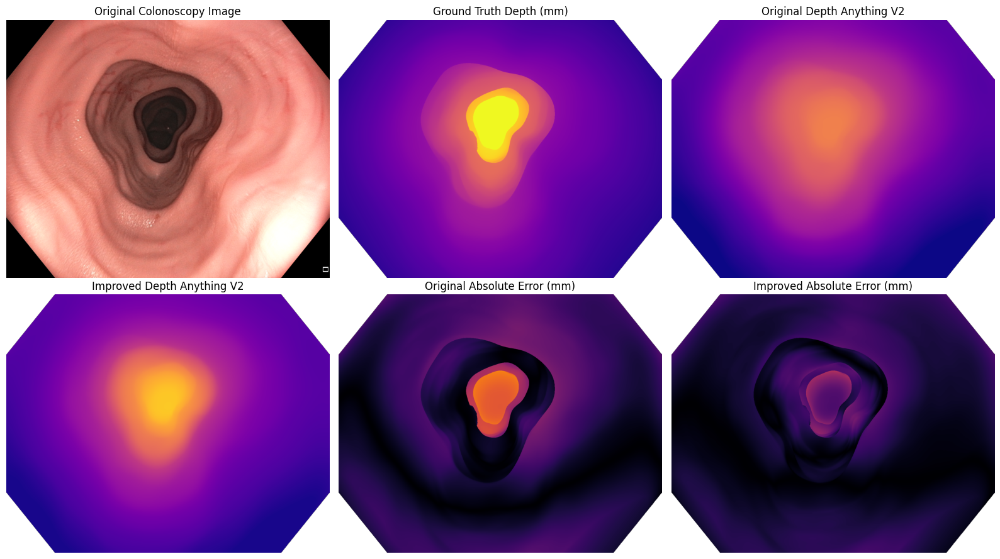

Original MAE: 7.4650087
Improved MAE: 5.1743804815394085
Figure saved to: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/final_depth_comparison.png


In [55]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Choose one test frame for visualization
frame = "0001"

# Load C3VD test image
rgb_bgr = cv2.imread(
    f"{test_folder}/{frame}_color.png"
)
rgb = cv2.cvtColor(rgb_bgr, cv2.COLOR_BGR2RGB)

# Load ground truth
gt_raw = cv2.imread(
    f"{test_folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
valid = gt_raw > 0

# Load pretrained model prediction
pred = np.load(
    f"{test_output}/{frame}_pred.npy"
)

# Original calibrated prediction
linear = np.clip(
    -scale * pred + offset,
    1e-3, 100.0
)

# Improved prediction using final correction
correction = np.interp(
    linear,
    [10, 30, 50, 70],
    final_corrections[:4]
)

improved = np.clip(
    linear + correction,
    1e-3, 100.0
)

# Mask invalid pixels
gt_display = np.where(valid, gt_mm, np.nan)
linear_display = np.where(valid, linear, np.nan)
improved_display = np.where(valid, improved, np.nan)

# Absolute error maps
linear_error = np.where(
    valid, np.abs(gt_mm - linear), np.nan
)

improved_error = np.where(
    valid, np.abs(gt_mm - improved), np.nan
)

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original Colonoscopy Image")

axes[0, 1].imshow(
    gt_display, cmap="plasma", vmin=0, vmax=100
)
axes[0, 1].set_title("Ground Truth Depth (mm)")

axes[0, 2].imshow(
    linear_display, cmap="plasma", vmin=0, vmax=100
)
axes[0, 2].set_title("Original Depth Anything V2")

axes[1, 0].imshow(
    improved_display, cmap="plasma", vmin=0, vmax=100
)
axes[1, 0].set_title("Improved Depth Anything V2")

axes[1, 1].imshow(
    linear_error, cmap="inferno", vmin=0, vmax=50
)
axes[1, 1].set_title("Original Absolute Error (mm)")

axes[1, 2].imshow(
    improved_error, cmap="inferno", vmin=0, vmax=50
)
axes[1, 2].set_title("Improved Absolute Error (mm)")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()

# Save to Google Drive
save_path = os.path.join(
    save_folder,
    "final_depth_comparison.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print errors for this frame
print(
    "Original MAE:",
    np.mean(np.abs(gt_mm[valid] - linear[valid]))
)

print(
    "Improved MAE:",
    np.mean(np.abs(gt_mm[valid] - improved[valid]))
)

print("Figure saved to:", save_path)

In [56]:
import numpy as np
import cv2

# Load one test frame
frame = "0001"

gt_raw = cv2.imread(
    f"{test_folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

pred = np.load(
    f"{test_output}/{frame}_pred.npy"
)

# Apply original calibration
linear = np.clip(
    -scale * pred + offset,
    1e-3, 100.0
)

# Apply smooth correction
improved = np.clip(
    linear + np.interp(
        linear,
        [10, 30, 50, 70],
        final_corrections[:4]
    ),
    1e-3, 100.0
)

# Evaluation mask
valid = gt_raw > 0

gt = gt_mm[valid].astype(np.float64)
prediction = improved[valid].astype(np.float64)

# Calculate metrics
absrel = np.mean(
    np.abs(gt - prediction) / gt
)

rmse = np.sqrt(
    np.mean((gt - prediction) ** 2)
)

delta = np.mean(
    np.maximum(
        gt / prediction,
        prediction / gt
    ) < 1.25
)

print("EVALUATION VERIFICATION")
print("-----------------------")
print("Valid pixels:", valid.sum())
print("AbsRel:", round(absrel, 6))
print("RMSE (mm):", round(rmse, 6))
print("Delta < 1.25:", round(delta, 6))

print("\nDepth mask:")
print("Zero-depth pixels excluded:", np.sum(gt_raw == 0))
print("100 mm pixels included:", np.sum(gt_raw == 65535))

EVALUATION VERIFICATION
-----------------------
Valid pixels: 1355951
AbsRel: 0.299395
RMSE (mm): 6.18745
Delta < 1.25: 0.51348

Depth mask:
Zero-depth pixels excluded: 102049
100 mm pixels included: 29867


In [57]:
import os
import cv2
import numpy as np

total_pixels = 0
total_absrel = 0.0
total_squared_error = 0.0
total_delta_correct = 0

for filename in sorted(os.listdir(test_output)):

    if not filename.endswith("_pred.npy"):
        continue

    pred = np.load(os.path.join(test_output, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    valid = gt_raw > 0

    linear = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    improved = np.clip(
        linear + np.interp(
            linear,
            [10, 30, 50, 70],
            final_corrections[:4]
        ),
        1e-3, 100.0
    )

    gt = gt_mm[valid].astype(np.float64)
    prediction = improved[valid].astype(np.float64)

    total_pixels += gt.size

    total_absrel += np.sum(
        np.abs(gt - prediction) / gt
    )

    total_squared_error += np.sum(
        (gt - prediction) ** 2
    )

    total_delta_correct += np.count_nonzero(
        np.maximum(
            gt / prediction,
            prediction / gt
        ) < 1.25
    )

global_absrel = total_absrel / total_pixels
global_rmse = np.sqrt(total_squared_error / total_pixels)
global_delta = total_delta_correct / total_pixels

print("GLOBAL PIXEL-WEIGHTED TEST RESULTS")
print("----------------------------------")
print("Total valid pixels:", total_pixels)
print("AbsRel:", round(global_absrel, 6))
print("RMSE (mm):", round(global_rmse, 6))
print("Delta < 1.25:", round(global_delta, 6))

GLOBAL PIXEL-WEIGHTED TEST RESULTS
----------------------------------
Total valid pixels: 139662953
AbsRel: 0.282546
RMSE (mm): 5.873254
Delta < 1.25: 0.544395


In [58]:
import os
import cv2
import numpy as np

frame_errors = []

for filename in sorted(os.listdir(test_output)):
    if not filename.endswith("_pred.npy"):
        continue

    frame = filename.replace("_pred.npy", "")

    pred = np.load(os.path.join(test_output, filename))

    gt_raw = cv2.imread(
        f"{test_folder}/{frame}_depth.tiff",
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    linear = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    improved = np.clip(
        linear + np.interp(
            linear,
            [10, 30, 50, 70],
            final_corrections[:4]
        ),
        1e-3, 100.0
    )

    rmse = np.sqrt(
        np.mean(
            (gt_mm[valid] - improved[valid]) ** 2
        )
    )

    frame_errors.append((frame, float(rmse)))

# Sort from highest to lowest error
frame_errors.sort(key=lambda x: x[1], reverse=True)

print("TOP 3 FAILURE CASES")
print("--------------------")

for frame, rmse in frame_errors[:3]:
    print(f"Frame {frame}: RMSE = {rmse:.4f} mm")

print("\nTOP 3 BEST CASES")
print("----------------")

for frame, rmse in frame_errors[-3:]:
    print(f"Frame {frame}: RMSE = {rmse:.4f} mm")

TOP 3 FAILURE CASES
--------------------
Frame 0072: RMSE = 7.0227 mm
Frame 0076: RMSE = 6.9582 mm
Frame 0078: RMSE = 6.8542 mm

TOP 3 BEST CASES
----------------
Frame 0091: RMSE = 4.8379 mm
Frame 0101: RMSE = 4.7737 mm
Frame 0102: RMSE = 4.6731 mm


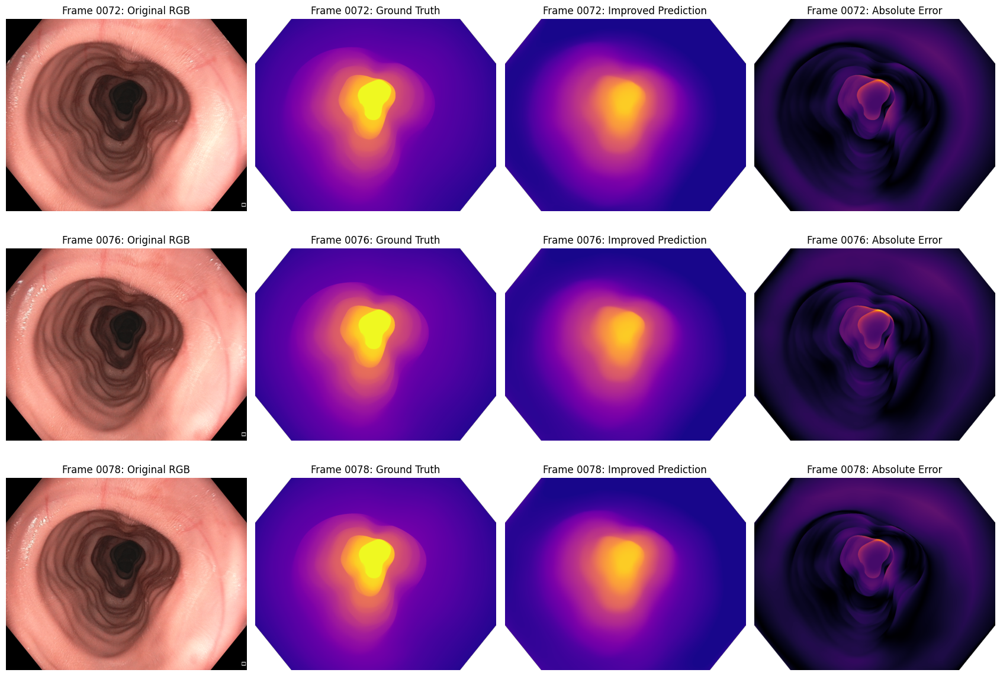

Failure-case figure saved to: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/failure_cases.png


In [59]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

failure_frames = ["0072", "0076", "0078"]

fig, axes = plt.subplots(3, 4, figsize=(17, 12))

for row, frame in enumerate(failure_frames):

    rgb = cv2.cvtColor(
        cv2.imread(f"{test_folder}/{frame}_color.png"),
        cv2.COLOR_BGR2RGB
    )

    gt_raw = cv2.imread(
        f"{test_folder}/{frame}_depth.tiff",
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    pred = np.load(f"{test_output}/{frame}_pred.npy")

    linear = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    improved = np.clip(
        linear + np.interp(
            linear,
            [10, 30, 50, 70],
            final_corrections[:4]
        ),
        1e-3, 100.0
    )

    error = np.abs(gt_mm - improved)

    images = [
        rgb,
        np.where(valid, gt_mm, np.nan),
        np.where(valid, improved, np.nan),
        np.where(valid, error, np.nan)
    ]

    titles = [
        "Original RGB",
        "Ground Truth",
        "Improved Prediction",
        "Absolute Error"
    ]

    for col in range(4):
        ax = axes[row, col]

        if col == 0:
            ax.imshow(images[col])
        else:
            ax.imshow(
                images[col],
                cmap="inferno" if col == 3 else "plasma",
                vmin=0,
                vmax=50 if col == 3 else 100
            )

        ax.set_title(f"Frame {frame}: {titles[col]}")
        ax.axis("off")

plt.tight_layout()

save_path = f"{save_folder}/failure_cases.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Failure-case figure saved to:", save_path)

In [60]:
import torch
from google.colab import drive

drive.mount('/content/drive')

print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU available: True
GPU: Tesla T4


In [61]:
# Dataset already prepared from your extracted Google Drive folders.
# Do not try to open missing .zip files.
from pathlib import Path
for name in ["trans_t1_a", "trans_t2_b"]:
    folder = Path("/content/C3VD") / name / name
    assert folder.is_dir() and list(folder.glob("*_color.png")), f"Missing prepared data: {folder}"
    print(name, "ready:", len(list(folder.glob("*_color.png"))), "RGB frames")


trans_t1_a ready: 61 RGB frames
trans_t2_b ready: 103 RGB frames


In [62]:
dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"
test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"

print("Development images:", len([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
]))

print("Test images:", len([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
]))

Development images: 61
Test images: 103


In [63]:
%cd /content

!git clone https://github.com/DepthAnything/Depth-Anything-V2.git

%cd /content/Depth-Anything-V2

/content
fatal: destination path 'Depth-Anything-V2' already exists and is not an empty directory.
/content/Depth-Anything-V2


In [64]:
!pip install -q -r requirements.txt

In [65]:
import os
import torch

print("Current directory:", os.getcwd())
print("Model code available:",
      os.path.exists("depth_anything_v2/dpt.py"))

print("GPU:", torch.cuda.get_device_name(0))

Current directory: /content/Depth-Anything-V2
Model code available: True
GPU: Tesla T4


In [66]:
%cd /content/Depth-Anything-V2

# Create folder for model weights
!mkdir -p checkpoints

# Download Depth Anything V2 Large pretrained weights
!wget -q --show-progress \
https://huggingface.co/depth-anything/Depth-Anything-V2-Large/resolve/main/depth_anything_v2_vitl.pth \
-O checkpoints/depth_anything_v2_vitl.pth

/content/Depth-Anything-V2
checkpoints/depth_a 100%[===================>]   1.25G  35.0MB/s    in 20s     


In [67]:
import os

model_path = "checkpoints/depth_anything_v2_vitl.pth"

print("Weights downloaded:", os.path.exists(model_path))
print("File size (GB):", round(os.path.getsize(model_path) / 1e9, 2))

Weights downloaded: True
File size (GB): 1.34


In [68]:
import torch
from depth_anything_v2.dpt import DepthAnythingV2

# Configure Depth Anything V2 Large
model_large = DepthAnythingV2(
    encoder='vitl',
    features=256,
    out_channels=[256, 512, 1024, 1024]
)

# Load pretrained weights
model_large.load_state_dict(
    torch.load(
        'checkpoints/depth_anything_v2_vitl.pth',
        map_location='cpu',
        weights_only=True
    )
)

# Move model to GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model_large = model_large.to(device).eval()

print("Model loaded successfully!")
print("Model: Depth Anything V2 Large")
print("Running on:", device)
print("GPU:", torch.cuda.get_device_name(0))

Model loaded successfully!
Model: Depth Anything V2 Large
Running on: cuda
GPU: Tesla T4


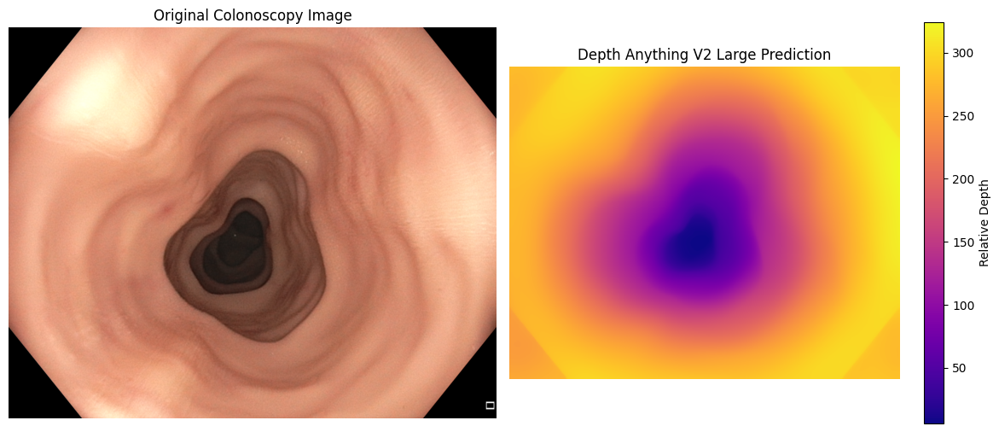

Prediction shape: (1080, 1350)
Minimum prediction: 5.9551625
Maximum prediction: 324.145


In [69]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load first C3VD development image
image_path = "/content/C3VD/trans_t1_a/trans_t1_a/0001_color.png"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Run Depth Anything V2 Large
with torch.inference_mode():
    predicted_large = model_large.infer_image(
        image,
        input_size=518
    )

# Display original image and prediction
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_large, cmap="plasma")
plt.title("Depth Anything V2 Large Prediction")
plt.colorbar(label="Relative Depth")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_large.shape)
print("Minimum prediction:", predicted_large.min())
print("Maximum prediction:", predicted_large.max())

In [70]:
import os
import cv2
import numpy as np
import torch

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"

large_output = "/content/C3VD/large_dev_predictions"
os.makedirs(large_output, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

model_large.eval()

for i, filename in enumerate(image_files):

    image = cv2.imread(
        os.path.join(dev_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_large.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    np.save(
        os.path.join(large_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(image_files):
        print(f"Processed {i + 1}/{len(image_files)}")

print("All Large model development predictions saved!")

Total development images: 61
Processed 10/61
Processed 20/61
Processed 30/61
Processed 40/61
Processed 50/61
Processed 60/61
Processed 61/61
All Large model development predictions saved!


In [71]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_large = []
y_large = []

prediction_files_large = sorted([
    f for f in os.listdir(large_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_large:

    # Load Large model prediction
    pred = np.load(
        os.path.join(large_output, filename)
    )

    # Load corresponding ground-truth depth
    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Use the same evaluation mask as Small
    valid = gt_raw > 0

    # Negative prediction reverses the depth direction
    X_large.append((-pred[valid]).reshape(-1, 1))
    y_large.append(gt_mm[valid])

X_large = np.concatenate(X_large)
y_large = np.concatenate(y_large)

# Fit linear calibration
large_calibrator = LinearRegression()
large_calibrator.fit(X_large, y_large)

large_scale = float(large_calibrator.coef_[0])
large_offset = float(large_calibrator.intercept_)

print("LARGE MODEL CALIBRATION")
print("-----------------------")
print("Development frames:", len(prediction_files_large))
print("Valid pixels:", len(y_large))
print("Scale:", large_scale)
print("Offset:", large_offset)
print("Calibration completed!")

LARGE MODEL CALIBRATION
-----------------------
Development frames: 61
Valid pixels: 82713011
Scale: 0.222745880484581
Offset: 75.89997863769531
Calibration completed!


In [72]:
import os
import cv2
import numpy as np

absrel_values = []
squared_errors = []
delta_values = []

for filename in prediction_files_large:

    pred = np.load(os.path.join(large_output, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Convert relative prediction into millimeters
    pred_mm = np.clip(
        -large_scale * pred + large_offset,
        1e-3,
        100.0
    )

    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # AbsRel
    absrel_values.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # Squared error for RMSE
    squared_errors.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_values.append(
        np.mean(ratio < 1.25)
    )

print("LARGE MODEL — DEVELOPMENT RESULTS")
print("----------------------------------")
print("AbsRel:", round(np.mean(absrel_values), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(squared_errors)), 4))
print("Delta < 1.25:", round(np.mean(delta_values), 4))

LARGE MODEL — DEVELOPMENT RESULTS
----------------------------------
AbsRel: 0.33
RMSE (mm): 8.3288
Delta < 1.25: 0.4827


In [73]:
import os
import cv2
import numpy as np
import torch

test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"
large_test_output = "/content/C3VD/large_test_predictions"

os.makedirs(large_test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model_large.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_large.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    np.save(
        os.path.join(large_test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All Large model test predictions saved!")

Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All Large model test predictions saved!


In [74]:
import os
import cv2
import numpy as np

mae_values = []
absrel_values = []
squared_errors = []
delta_values = []

prediction_files = sorted([
    f for f in os.listdir(large_test_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files:

    # Load Large model prediction
    pred = np.load(
        os.path.join(large_test_output, filename)
    )

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth into millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply development-set calibration
    pred_mm = np.clip(
        -large_scale * pred + large_offset,
        1e-3,
        100.0
    )

    # Same evaluation mask as Small model
    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # MAE
    mae_values.append(
        np.mean(np.abs(gt - prediction))
    )

    # AbsRel
    absrel_values.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # RMSE
    squared_errors.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_values.append(
        np.mean(ratio < 1.25)
    )

print("DEPTH ANYTHING V2 LARGE — TEST RESULTS")
print("---------------------------------------")
print("Test frames:", len(prediction_files))
print("MAE (mm):", round(np.mean(mae_values), 4))
print("AbsRel:", round(np.mean(absrel_values), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(squared_errors)), 4))
print("Delta < 1.25:", round(np.mean(delta_values), 4))

DEPTH ANYTHING V2 LARGE — TEST RESULTS
---------------------------------------
Test frames: 103
MAE (mm): 5.0184
AbsRel: 0.2838
RMSE (mm): 7.2077
Delta < 1.25: 0.5531


In [75]:
import os
import json
import shutil

save_large = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2/Large"
)

os.makedirs(save_large, exist_ok=True)

# Save development and test predictions
for source, folder_name in [
    (large_output, "dev_predictions"),
    (large_test_output, "test_predictions")
]:
    shutil.copytree(
        source,
        os.path.join(save_large, folder_name),
        dirs_exist_ok=True
    )

# Save calibration and evaluation results
large_results = {
    "model": "Depth Anything V2 Large",
    "encoder": "vitl",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(large_scale),
    "offset": float(large_offset),
    "MAE_mm": float(np.mean(mae_values)),
    "AbsRel": float(np.mean(absrel_values)),
    "RMSE_mm": float(np.sqrt(np.mean(squared_errors))),
    "Delta_1.25": float(np.mean(delta_values)),
    "valid_mask": "gt_raw > 0",
    "input_size": 518
}

with open(
    os.path.join(save_large, "large_results.json"), "w"
) as f:
    json.dump(large_results, f, indent=4)

print("Large model results saved successfully!")
print("Location:", save_large)

Large model results saved successfully!
Location: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/Large


In [76]:
%cd /content/Depth-Anything-V2

# Create a separate folder for metric-depth weights
!mkdir -p checkpoints_metric

# Download Large Indoor pretrained weights
!wget -q --show-progress \
https://huggingface.co/depth-anything/Depth-Anything-V2-Metric-Indoor-Large/resolve/main/depth_anything_v2_metric_hypersim_vitl.pth \
-O checkpoints_metric/depth_anything_v2_metric_hypersim_vitl.pth

/content/Depth-Anything-V2


In [77]:
import os

indoor_path = (
    "checkpoints_metric/"
    "depth_anything_v2_metric_hypersim_vitl.pth"
)

print("Weights downloaded:", os.path.exists(indoor_path))

if os.path.exists(indoor_path):
    print(
        "File size (GB):",
        round(os.path.getsize(indoor_path) / 1e9, 2)
    )

Weights downloaded: True
File size (GB): 0.0


In [78]:
%cd /content/Depth-Anything-V2

!pip install -q huggingface_hub

from huggingface_hub import hf_hub_download
import os

indoor_path = hf_hub_download(
    repo_id="depth-anything/Depth-Anything-V2-Metric-Hypersim-Large",
    filename="depth_anything_v2_metric_hypersim_vitl.pth",
    local_dir="/content/Depth-Anything-V2/checkpoints_metric"
)

print("Downloaded:", os.path.exists(indoor_path))
print("File size (GB):", round(os.path.getsize(indoor_path) / 1e9, 2))

/content/Depth-Anything-V2


depth_anything_v2_metric_hypersim_vitl.p(…): reconstructing file:   0%|          |  0.00B / 1.34GB            

depth_anything_v2_metric_hypersim_vitl.p(…): downloading bytes:           |  0.00B            

Downloaded: True
File size (GB): 1.34


In [79]:
import sys
import torch

# Remove previously imported standard model modules
for name in list(sys.modules):
    if name == "depth_anything_v2" or name.startswith("depth_anything_v2."):
        del sys.modules[name]

# Prioritize the metric-depth implementation
metric_path = "/content/Depth-Anything-V2/metric_depth"

sys.path = [p for p in sys.path if p != metric_path]
sys.path.insert(0, metric_path)

# Import metric-depth architecture
from depth_anything_v2.dpt import DepthAnythingV2 as MetricDepthAnythingV2

# Initialize Large Indoor
model_indoor = MetricDepthAnythingV2(
    encoder="vitl",
    features=256,
    out_channels=[256, 512, 1024, 1024],
    max_depth=20
)

# Load pretrained weights
model_indoor.load_state_dict(
    torch.load(
        indoor_path,
        map_location="cpu",
        weights_only=True
    )
)

model_indoor = model_indoor.to("cuda").eval()

print("Large Indoor model loaded successfully!")
print("Running on:", next(model_indoor.parameters()).device)

Large Indoor model loaded successfully!
Running on: cuda:0


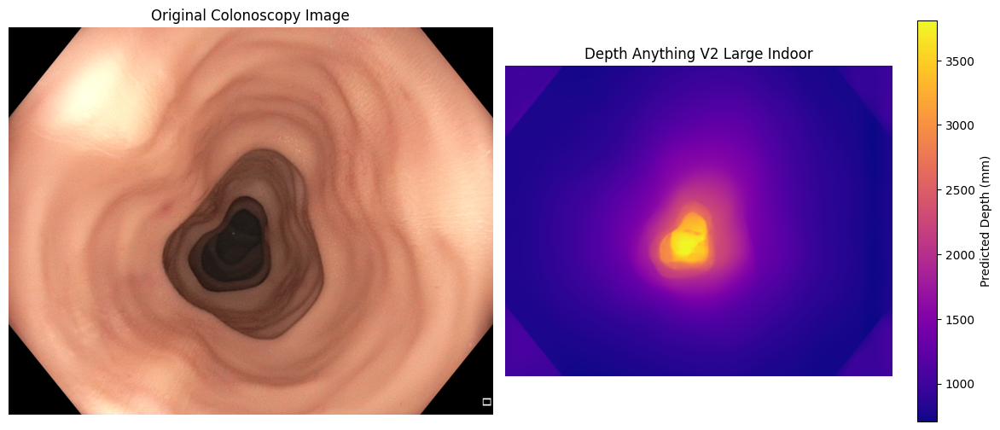

Prediction shape: (1080, 1350)
Minimum depth (mm): 706.9086
Maximum depth (mm): 3808.3015


In [80]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load first C3VD development image
image_path = "/content/C3VD/trans_t1_a/trans_t1_a/0001_color.png"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Generate Indoor model prediction
with torch.inference_mode():
    predicted_indoor = model_indoor.infer_image(
        image,
        input_size=518
    )

# Convert meters to millimeters
predicted_indoor_mm = predicted_indoor * 1000.0

# Display results
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_indoor_mm, cmap="plasma")
plt.title("Depth Anything V2 Large Indoor")
plt.colorbar(label="Predicted Depth (mm)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_indoor_mm.shape)
print("Minimum depth (mm):", predicted_indoor_mm.min())
print("Maximum depth (mm):", predicted_indoor_mm.max())

In [81]:
import os
import cv2
import numpy as np
import torch

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"

indoor_dev_output = "/content/C3VD/indoor_dev_predictions"
os.makedirs(indoor_dev_output, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

model_indoor.eval()

for i, filename in enumerate(image_files):

    image = cv2.imread(
        os.path.join(dev_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_indoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw metric predictions in meters
    np.save(
        os.path.join(indoor_dev_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(image_files):
        print(f"Processed {i + 1}/{len(image_files)}")

print("All Large Indoor development predictions saved!")

Total development images: 61
Processed 10/61
Processed 20/61
Processed 30/61
Processed 40/61
Processed 50/61
Processed 60/61
Processed 61/61
All Large Indoor development predictions saved!


In [82]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_indoor = []
y_indoor = []

prediction_files_indoor = sorted([
    f for f in os.listdir(indoor_dev_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_indoor:

    # Load Indoor prediction (meters)
    pred = np.load(
        os.path.join(indoor_dev_output, filename)
    )

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Same mask as previous models
    valid = gt_raw > 0

    # Convert Indoor prediction to millimeters
    pred_mm = pred * 1000.0

    X_indoor.append(pred_mm[valid].reshape(-1, 1))
    y_indoor.append(gt_mm[valid])

X_indoor = np.concatenate(X_indoor)
y_indoor = np.concatenate(y_indoor)

# Fit linear regression
indoor_calibrator = LinearRegression()
indoor_calibrator.fit(X_indoor, y_indoor)

indoor_scale = float(indoor_calibrator.coef_[0])
indoor_offset = float(indoor_calibrator.intercept_)

print("LARGE INDOOR CALIBRATION")
print("------------------------")
print("Development frames:", len(prediction_files_indoor))
print("Valid pixels:", len(y_indoor))
print("Scale:", indoor_scale)
print("Offset:", indoor_offset)
print("Calibration completed!")

LARGE INDOOR CALIBRATION
------------------------
Development frames: 61
Valid pixels: 82713011
Scale: 0.031549133360385895
Offset: -13.024480819702148
Calibration completed!


In [83]:
import os
import cv2
import numpy as np

mae_indoor = []
absrel_indoor = []
sqerr_indoor = []
delta_indoor = []

for filename in prediction_files_indoor:

    pred = np.load(
        os.path.join(indoor_dev_output, filename)
    )

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Convert meters to millimeters and calibrate
    pred_mm = np.clip(
        indoor_scale * (pred * 1000.0) + indoor_offset,
        1e-3,
        100.0
    )

    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    mae_indoor.append(
        np.mean(np.abs(gt - prediction))
    )

    absrel_indoor.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    sqerr_indoor.append(
        np.mean((gt - prediction) ** 2)
    )

    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_indoor.append(
        np.mean(ratio < 1.25)
    )

print("LARGE INDOOR — DEVELOPMENT RESULTS")
print("-----------------------------------")
print("MAE (mm):", round(np.mean(mae_indoor), 4))
print("AbsRel:", round(np.mean(absrel_indoor), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(sqerr_indoor)), 4))
print("Delta < 1.25:", round(np.mean(delta_indoor), 4))

LARGE INDOOR — DEVELOPMENT RESULTS
-----------------------------------
MAE (mm): 4.5518
AbsRel: 0.3052
RMSE (mm): 5.9881
Delta < 1.25: 0.5407


In [84]:
import os
import cv2
import numpy as np
import torch

test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"
indoor_test_output = "/content/C3VD/indoor_test_predictions"

os.makedirs(indoor_test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model_indoor.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_indoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw predictions in meters
    np.save(
        os.path.join(indoor_test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All Large Indoor test predictions saved!")


Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All Large Indoor test predictions saved!


In [85]:
import os
import cv2
import numpy as np

mae_indoor_test = []
absrel_indoor_test = []
sqerr_indoor_test = []
delta_indoor_test = []

prediction_files_indoor_test = sorted([
    f for f in os.listdir(indoor_test_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_indoor_test:

    # Load Indoor model prediction (meters)
    pred = np.load(
        os.path.join(indoor_test_output, filename)
    )

    # Load corresponding ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply calibration learned from development data
    pred_mm = np.clip(
        indoor_scale * (pred * 1000.0) + indoor_offset,
        1e-3,
        100.0
    )

    # Same valid-pixel mask as previous models
    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # MAE
    mae_indoor_test.append(
        np.mean(np.abs(gt - prediction))
    )

    # AbsRel
    absrel_indoor_test.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # RMSE
    sqerr_indoor_test.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_indoor_test.append(
        np.mean(ratio < 1.25)
    )

print("DEPTH ANYTHING V2 LARGE INDOOR — TEST RESULTS")
print("-" * 55)
print("Test frames:", len(prediction_files_indoor_test))
print("MAE (mm):", round(np.mean(mae_indoor_test), 4))
print("AbsRel:", round(np.mean(absrel_indoor_test), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(sqerr_indoor_test)), 4))
print("Delta < 1.25:", round(np.mean(delta_indoor_test), 4))

DEPTH ANYTHING V2 LARGE INDOOR — TEST RESULTS
-------------------------------------------------------
Test frames: 103
MAE (mm): 5.4559
AbsRel: 0.2676
RMSE (mm): 7.7213
Delta < 1.25: 0.48


In [86]:
import os
import json
import shutil
import numpy as np

save_indoor = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2/Large_Indoor"
)

os.makedirs(save_indoor, exist_ok=True)

# Save raw predictions
for source, folder_name in [
    (indoor_dev_output, "dev_predictions"),
    (indoor_test_output, "test_predictions")
]:
    shutil.copytree(
        source,
        os.path.join(save_indoor, folder_name),
        dirs_exist_ok=True
    )

# Save calibration and evaluation results
indoor_results = {
    "model": "Depth Anything V2 Large Indoor",
    "encoder": "vitl",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(indoor_scale),
    "offset": float(indoor_offset),
    "MAE_mm": float(np.mean(mae_indoor_test)),
    "AbsRel": float(np.mean(absrel_indoor_test)),
    "RMSE_mm": float(np.sqrt(np.mean(sqerr_indoor_test))),
    "Delta_1.25": float(np.mean(delta_indoor_test)),
    "valid_mask": "gt_raw > 0",
    "input_size": 518
}

with open(
    os.path.join(save_indoor, "indoor_results.json"), "w"
) as f:
    json.dump(indoor_results, f, indent=4)

print("Large Indoor results saved successfully!")
print("Location:", save_indoor)

Large Indoor results saved successfully!
Location: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/Large_Indoor


In [87]:
%cd /content/Depth-Anything-V2

from huggingface_hub import hf_hub_download
import os

# Download official Large Outdoor weights
outdoor_path = hf_hub_download(
    repo_id="depth-anything/Depth-Anything-V2-Metric-VKITTI-Large",
    filename="depth_anything_v2_metric_vkitti_vitl.pth",
    local_dir="/content/Depth-Anything-V2/checkpoints_metric"
)

print("Weights downloaded:", os.path.exists(outdoor_path))
print("File size (GB):", round(os.path.getsize(outdoor_path) / 1e9, 2))

/content/Depth-Anything-V2


depth_anything_v2_metric_vkitti_vitl.pth: reconstructing file:   0%|          |  0.00B / 1.34GB            

depth_anything_v2_metric_vkitti_vitl.pth: downloading bytes:           |  0.00B            

Weights downloaded: True
File size (GB): 1.34


In [88]:
import torch
import gc

# Free GPU memory used by Indoor model
model_indoor = model_indoor.to("cpu")
torch.cuda.empty_cache()
gc.collect()

# Reuse the metric-depth architecture imported earlier
model_outdoor = MetricDepthAnythingV2(
    encoder="vitl",
    features=256,
    out_channels=[256, 512, 1024, 1024],
    max_depth=80
)

# Load Outdoor pretrained weights
model_outdoor.load_state_dict(
    torch.load(
        outdoor_path,
        map_location="cpu",
        weights_only=True
    )
)

# Move model to T4 GPU
model_outdoor = model_outdoor.to("cuda").eval()

print("Large Outdoor model loaded successfully!")
print("Running on:", next(model_outdoor.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))

Large Outdoor model loaded successfully!
Running on: cuda:0
GPU: Tesla T4


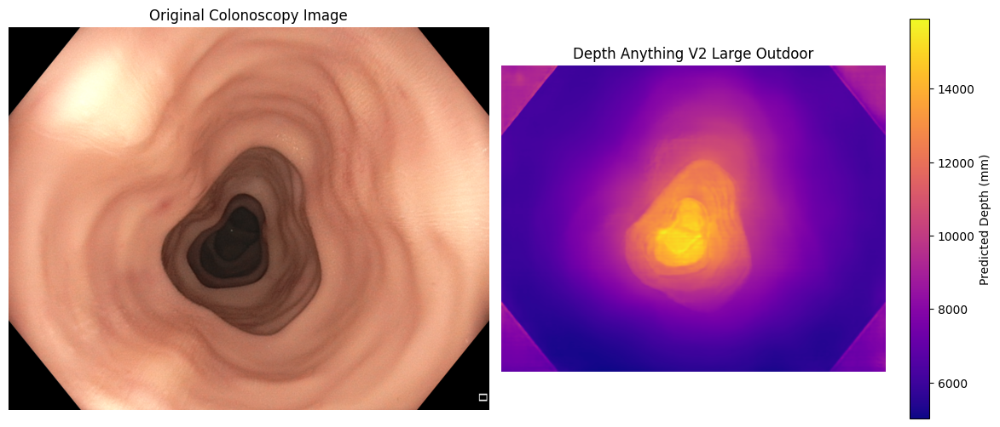

Prediction shape: (1080, 1350)
Minimum depth (mm): 5015.5044
Maximum depth (mm): 15911.468


In [89]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load C3VD development image
image_path = "/content/C3VD/trans_t1_a/trans_t1_a/0001_color.png"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Generate Outdoor model prediction
with torch.inference_mode():
    predicted_outdoor = model_outdoor.infer_image(
        image,
        input_size=518
    )

# Convert meters to millimeters
predicted_outdoor_mm = predicted_outdoor * 1000.0

# Display results
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_outdoor_mm, cmap="plasma")
plt.title("Depth Anything V2 Large Outdoor")
plt.colorbar(label="Predicted Depth (mm)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_outdoor_mm.shape)
print("Minimum depth (mm):", predicted_outdoor_mm.min())
print("Maximum depth (mm):", predicted_outdoor_mm.max())

In [90]:
import os
import cv2
import numpy as np
import torch

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"

outdoor_dev_output = "/content/C3VD/outdoor_dev_predictions"
os.makedirs(outdoor_dev_output, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

model_outdoor.eval()

for i, filename in enumerate(image_files):

    image = cv2.imread(
        os.path.join(dev_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_outdoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw predictions in meters
    np.save(
        os.path.join(outdoor_dev_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(image_files):
        print(f"Processed {i + 1}/{len(image_files)}")

print("All Large Outdoor development predictions saved!")

Total development images: 61
Processed 10/61
Processed 20/61
Processed 30/61
Processed 40/61
Processed 50/61
Processed 60/61
Processed 61/61
All Large Outdoor development predictions saved!


In [91]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_outdoor = []
y_outdoor = []

prediction_files_outdoor = sorted([
    f for f in os.listdir(outdoor_dev_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_outdoor:

    # Load Outdoor prediction (meters)
    pred = np.load(
        os.path.join(outdoor_dev_output, filename)
    )

    # Load corresponding ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Same valid-pixel mask as previous models
    valid = gt_raw > 0

    # Convert Outdoor prediction to millimeters
    pred_mm = pred * 1000.0

    X_outdoor.append(pred_mm[valid].reshape(-1, 1))
    y_outdoor.append(gt_mm[valid])

X_outdoor = np.concatenate(X_outdoor)
y_outdoor = np.concatenate(y_outdoor)

# Fit linear regression
outdoor_calibrator = LinearRegression()
outdoor_calibrator.fit(X_outdoor, y_outdoor)

outdoor_scale = float(outdoor_calibrator.coef_[0])
outdoor_offset = float(outdoor_calibrator.intercept_)

print("LARGE OUTDOOR CALIBRATION")
print("-------------------------")
print("Development frames:", len(prediction_files_outdoor))
print("Valid pixels:", len(y_outdoor))
print("Scale:", outdoor_scale)
print("Offset:", outdoor_offset)
print("Calibration completed!")

LARGE OUTDOOR CALIBRATION
-------------------------
Development frames: 61
Valid pixels: 82713011
Scale: 0.007487837690860033
Offset: -34.026344299316406
Calibration completed!


In [92]:
import os
import cv2
import numpy as np

mae_outdoor = []
absrel_outdoor = []
sqerr_outdoor = []
delta_outdoor = []

for filename in prediction_files_outdoor:

    # Load Outdoor prediction (meters)
    pred = np.load(
        os.path.join(outdoor_dev_output, filename)
    )

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Convert meters to millimeters and apply calibration
    pred_mm = np.clip(
        outdoor_scale * (pred * 1000.0) + outdoor_offset,
        1e-3,
        100.0
    )

    # Same evaluation mask as previous models
    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # MAE
    mae_outdoor.append(
        np.mean(np.abs(gt - prediction))
    )

    # AbsRel
    absrel_outdoor.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # RMSE
    sqerr_outdoor.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_outdoor.append(
        np.mean(ratio < 1.25)
    )

print("LARGE OUTDOOR — DEVELOPMENT RESULTS")
print("------------------------------------")
print("MAE (mm):", round(np.mean(mae_outdoor), 4))
print("AbsRel:", round(np.mean(absrel_outdoor), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(sqerr_outdoor)), 4))
print("Delta < 1.25:", round(np.mean(delta_outdoor), 4))

LARGE OUTDOOR — DEVELOPMENT RESULTS
------------------------------------
MAE (mm): 6.677
AbsRel: 0.4046
RMSE (mm): 8.2276
Delta < 1.25: 0.3874


In [93]:
import os
import cv2
import numpy as np
import torch

test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"
outdoor_test_output = "/content/C3VD/outdoor_test_predictions"

os.makedirs(outdoor_test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model_outdoor.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_outdoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw predictions in meters
    np.save(
        os.path.join(outdoor_test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All Large Outdoor test predictions saved!")

Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All Large Outdoor test predictions saved!


In [94]:
import os
import cv2
import numpy as np

mae_outdoor_test = []
absrel_outdoor_test = []
sqerr_outdoor_test = []
delta_outdoor_test = []

prediction_files_outdoor_test = sorted([
    f for f in os.listdir(outdoor_test_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_outdoor_test:

    pred = np.load(
        os.path.join(outdoor_test_output, filename)
    )

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply calibration learned from development data
    pred_mm = np.clip(
        outdoor_scale * (pred * 1000.0) + outdoor_offset,
        1e-3,
        100.0
    )

    # Same valid-pixel mask as previous models
    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # MAE
    mae_outdoor_test.append(
        np.mean(np.abs(gt - prediction))
    )

    # AbsRel
    absrel_outdoor_test.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # RMSE
    sqerr_outdoor_test.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_outdoor_test.append(
        np.mean(ratio < 1.25)
    )

print("DEPTH ANYTHING V2 LARGE OUTDOOR — TEST RESULTS")
print("-" * 55)
print("Test frames:", len(prediction_files_outdoor_test))
print("MAE (mm):", round(np.mean(mae_outdoor_test), 4))
print("AbsRel:", round(np.mean(absrel_outdoor_test), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(sqerr_outdoor_test)), 4))
print("Delta < 1.25:", round(np.mean(delta_outdoor_test), 4))

DEPTH ANYTHING V2 LARGE OUTDOOR — TEST RESULTS
-------------------------------------------------------
Test frames: 103
MAE (mm): 5.8892
AbsRel: 0.3146
RMSE (mm): 7.7711
Delta < 1.25: 0.4456


In [95]:
import os
import json
import shutil
import numpy as np

save_outdoor = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2/Large_Outdoor"
)

os.makedirs(save_outdoor, exist_ok=True)

# Save development and test predictions
for source, folder_name in [
    (outdoor_dev_output, "dev_predictions"),
    (outdoor_test_output, "test_predictions")
]:
    shutil.copytree(
        source,
        os.path.join(save_outdoor, folder_name),
        dirs_exist_ok=True
    )

# Save calibration and evaluation results
outdoor_results = {
    "model": "Depth Anything V2 Large Outdoor",
    "encoder": "vitl",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(outdoor_scale),
    "offset": float(outdoor_offset),
    "MAE_mm": float(np.mean(mae_outdoor_test)),
    "AbsRel": float(np.mean(absrel_outdoor_test)),
    "RMSE_mm": float(np.sqrt(np.mean(sqerr_outdoor_test))),
    "Delta_1.25": float(np.mean(delta_outdoor_test)),
    "valid_mask": "gt_raw > 0",
    "input_size": 518
}

with open(
    os.path.join(save_outdoor, "outdoor_results.json"), "w"
) as f:
    json.dump(outdoor_results, f, indent=4)

print("Large Outdoor results saved successfully!")
print("Location:", save_outdoor)

Large Outdoor results saved successfully!
Location: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/Large_Outdoor


In [96]:
import os
import pandas as pd

save_folder = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2"
)

os.makedirs(save_folder, exist_ok=True)

data = [
    ["Constant Median", 12.9760, 0.5655, 21.2086, 0.2704],
    ["Small + Linear", 6.4007, 0.3700, 8.7136, 0.4162],
    ["Small + Smooth Correction", 4.6530, 0.2825, 5.8733, 0.5444],
    ["Large + Linear", 5.0184, 0.2838, 7.2077, 0.5531],
    ["Large Indoor + Linear", 5.4559, 0.2676, 7.7213, 0.4800],
    ["Large Outdoor + Linear", 5.8892, 0.3146, 7.7711, 0.4456]
]

df = pd.DataFrame(
    data,
    columns=[
        "Model",
        "MAE_mm",
        "AbsRel",
        "RMSE_mm",
        "Delta_1.25"
    ]
)

save_path = os.path.join(
    save_folder,
    "all_models_comparison.csv"
)

df.to_csv(save_path, index=False)

print(df.to_string(index=False))
print("\nSaved to:", save_path)

                    Model  MAE_mm  AbsRel  RMSE_mm  Delta_1.25
          Constant Median 12.9760  0.5655  21.2086      0.2704
           Small + Linear  6.4007  0.3700   8.7136      0.4162
Small + Smooth Correction  4.6530  0.2825   5.8733      0.5444
           Large + Linear  5.0184  0.2838   7.2077      0.5531
    Large Indoor + Linear  5.4559  0.2676   7.7213      0.4800
   Large Outdoor + Linear  5.8892  0.3146   7.7711      0.4456

Saved to: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/all_models_comparison.csv


# Novelty: Specular-reliability-weighted illumination correction (DAv2 Small)

**Independent, appended experiment.** Earlier cells remain unchanged. Uses saved raw Depth Anything V2 **Small** predictions and RGB frames. No model retraining. All parameters and hyperparameters are determined on `trans_t1_a` (61 frames); `trans_t2_b` (103 frames) is held out for final evaluation. The raw predictor output is a relative inverse-depth-like score, not metric depth. Brightness is an appearance cue, **not** a calibrated inverse-square distance measurement.

Four fair ablations: (A) DAv2 + fixed linear calibration, (B) A + brightness, (C) A + reliability-weighted brightness, (D) A + brightness + reliability weighting + a depth–brightness interaction. All use **identical development-only fitting** and identical evaluation masks. The original notebook's existing smooth correction is separate and is not silently replaced.

**Run these appended cells in order.** First mount Drive and ensure the raw `*_pred.npy` files exist in the local or saved Drive prediction folders. These cells do not require the pretrained network in memory.

In [97]:
from pathlib import Path
import os, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    pass

# Paths from YOUR uploaded Depth_Anything_V2_C3VD.ipynb
DATA_BASE = Path('/content/C3VD')
DEV_RGB = DATA_BASE / 'trans_t1_a' / 'trans_t1_a'
TEST_RGB = DATA_BASE / 'trans_t2_b' / 'trans_t2_b'
SAVED_BASE = Path('/content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2')
OUT = SAVED_BASE / 'Specular_Illumination_Novelty'
OUT.mkdir(parents=True, exist_ok=True)

def find_pred_folder(seq):
    local = DATA_BASE / ('dev_predictions' if seq=='dev' else 'test_predictions')
    saved = SAVED_BASE / ('dev_predictions' if seq=='dev' else 'test_predictions')
    for folder in (local, saved):
        if folder.is_dir() and len(list(folder.glob('*_pred.npy'))) > 0:
            return folder
    raise FileNotFoundError(f'No raw DAv2 Small predictions for {seq}. Run original cells 18/22 or restore saved predictions.')

DEV_PRED = find_pred_folder('dev')
TEST_PRED = find_pred_folder('test')
for folder in [DEV_RGB,TEST_RGB]:
    if not folder.is_dir():
        raise FileNotFoundError(f'Missing extracted C3VD folder: {folder}. Run original dataset extraction cells first.')
print('Development images:', DEV_RGB)
print('Test images:', TEST_RGB)
print('Development predictions:', DEV_PRED)
print('Test predictions:', TEST_PRED)
print('Novelty output:', OUT)

Development images: /content/C3VD/trans_t1_a/trans_t1_a
Test images: /content/C3VD/trans_t2_b/trans_t2_b
Development predictions: /content/C3VD/dev_predictions
Test predictions: /content/C3VD/test_predictions
Novelty output: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/Specular_Illumination_Novelty


In [98]:
# Inspect exact pairing and GT encoding before calculating metrics.
# This reproduces the original notebook's conversion; verify it against C3VD documentation.
GT_MM_PER_UINT16 = 100.0 / 65535.0

def collect_records(rgb_dir, pred_dir, expected):
    paths = sorted(pred_dir.glob('*_pred.npy'))
    records = []
    for p in paths:
        stem = p.name[:-len('_pred.npy')]
        rgb_path = rgb_dir / (stem + '_color.png')
        gt_path = rgb_dir / (stem + '_depth.tiff')
        if not rgb_path.is_file() or not gt_path.is_file():
            raise FileNotFoundError(f'Missing RGB or GT for prediction {p.name}: {rgb_path} / {gt_path}')
        records.append((stem,p,rgb_path,gt_path))
    if len(records)!=expected:
        raise ValueError(f'Expected {expected} frames, found {len(records)} in {pred_dir}')
    return records

dev_records = collect_records(DEV_RGB,DEV_PRED,61)
test_records = collect_records(TEST_RGB,TEST_PRED,103)
raw_check = cv2.imread(str(dev_records[0][3]),cv2.IMREAD_UNCHANGED)
print('Example GT:', dev_records[0][3].name, raw_check.dtype, raw_check.shape,
      'min/max:',np.nanmin(raw_check),np.nanmax(raw_check))
assert raw_check.dtype == np.uint16 and raw_check.ndim==2, 'Verify TIFF format and conversion before proceeding'
print('Conversion used: uint16 * 100 / 65535 (mm). VERIFY against official dataset documentation.')

Example GT: 0000_depth.tiff uint16 (1080, 1350) min/max: 0 65535
Conversion used: uint16 * 100 / 65535 (mm). VERIFY against official dataset documentation.


In [99]:
# Reliable illumination cue and specular/shadow gating.
def image_features(rgb):
    x = rgb.astype(np.float32)/255.0
    lin = np.where(x<=0.04045,x/12.92,((x+0.055)/1.055)**2.4)
    luminance = (0.2126*lin[:,:,0]+0.7152*lin[:,:,1]+0.0722*lin[:,:,2]).astype(np.float32)
    hsv = cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV)
    sat = hsv[:,:,1].astype(np.float32)/255.0
    val = hsv[:,:,2].astype(np.float32)/255.0
    # Fixed thresholds, not tuned on test labels. High brightness + low saturation suggests highlights.
    specular = (val>0.92)&(sat<0.26)
    shadow = val<0.10
    # Continuous reliability in [0,1] to downweight saturation and deep shadows.
    bright_gate = np.clip((0.97-val)/0.12,0,1)
    dark_gate = np.clip((val-0.08)/0.15,0,1)
    reliability = (bright_gate*dark_gate).astype(np.float32)
    reliability[specular|shadow]=0
    # Brightness is standardized globally during regression, not per test frame.
    return luminance, reliability, specular, shadow

def load_record(record):
    _,pred_path,rgb_path,gt_path=record
    bgr=cv2.imread(str(rgb_path),cv2.IMREAD_COLOR)
    raw=cv2.imread(str(gt_path),cv2.IMREAD_UNCHANGED)
    if bgr is None or raw is None: raise ValueError(f'Cannot load {record}')
    rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
    gt=raw.astype(np.float32)*GT_MM_PER_UINT16
    pred=np.load(pred_path).astype(np.float32)
    if pred.shape!=gt.shape or rgb.shape[:2]!=gt.shape:
        raise ValueError(f'Image/prediction/GT shape mismatch for {record[0]}')
    valid=(raw>0)&(raw<65535)&np.isfinite(pred)
    lum,rel,spec,shadow=image_features(rgb)
    return rgb,pred,gt,valid,lum,rel,spec,shadow

print('First dev sample shapes:',[(x.shape if hasattr(x,'shape') else type(x)) for x in load_record(dev_records[0])])

First dev sample shapes: [(1080, 1350, 3), (1080, 1350), (1080, 1350), (1080, 1350), (1080, 1350), (1080, 1350), (1080, 1350), (1080, 1350)]


In [100]:
# Define four ablation feature sets. Reliability affects only illumination terms;
# baseline depth calibration is always present. A raw interaction is included only in D.
MODES = {
 'A_global_linear': 'base',
 'B_brightness': 'brightness',
 'C_reliability_weighted': 'weighted',
 'D_combined_interaction': 'combined',
}

def design_matrix(pred,lum,rel,mode):
    p=pred.reshape(-1).astype(np.float64)
    b=lum.reshape(-1).astype(np.float64)
    w=rel.reshape(-1).astype(np.float64)
    cols=[p]
    if mode=='brightness': cols.append(b)
    elif mode=='weighted': cols.append(w*b)
    elif mode=='combined': cols.extend([b,w*b,w*b*p])
    return np.column_stack(cols)

def make_samples(records, max_pixels_per_frame=2500, seed=42):
    rng=np.random.default_rng(seed)
    sample=[]
    for rec in records:
        rgb,pred,gt,valid,lum,rel,_,_=load_record(rec)
        idx=np.flatnonzero(valid.ravel())
        if not len(idx): raise ValueError(f'No valid GT pixels in {rec[0]}')
        take=rng.choice(idx,size=min(max_pixels_per_frame,len(idx)),replace=False)
        sample.append((pred,gt,lum,rel,take))
    return sample

def fit_variant(samples,mode,alpha):
    X=np.concatenate([design_matrix(p,b,w,mode)[idx] for p,g,b,w,idx in samples])
    y=np.concatenate([g.ravel()[idx] for p,g,b,w,idx in samples])
    reg=make_pipeline(StandardScaler(),Ridge(alpha=alpha))
    reg.fit(X,y)
    return reg

def predict_variant(reg,pred,lum,rel,mode):
    x=design_matrix(pred,lum,rel,mode)
    y=reg.predict(x).reshape(pred.shape)
    return np.maximum(y,0.1).astype(np.float32)

def metrics(gt,pred,valid):
    g=gt[valid].astype(np.float64); p=pred[valid].astype(np.float64)
    if not len(g) or not np.isfinite(p).all() or np.any(p<=0): raise ValueError('Invalid evaluation pixels')
    return dict(MAE_mm=np.mean(abs(g-p)),AbsRel=np.mean(abs(g-p)/g),
                RMSE_mm=np.sqrt(np.mean((g-p)**2)),
                Delta1=np.mean(np.maximum(g/p,p/g)<1.25))

In [101]:
# Temporal block validation ONLY on development sequence (no test labels).
# Select one shared ridge alpha across all methods to avoid model-specific test tuning.
# Non-overlapping contiguous frames reduce adjacent-frame leakage.
ALPHAS=[1.0,100.0,10000.0]
folds=[(np.arange(0,40),np.arange(40,61)),
       (np.arange(21,61),np.arange(0,21))]
cv=[]
for alpha in ALPHAS:
    for label,mode in MODES.items():
        for fold_id,(train_idx,val_idx) in enumerate(folds):
            train_sample=make_samples([dev_records[i] for i in train_idx],seed=42)
            reg=fit_variant(train_sample,mode,alpha)
            frame_metrics=[]
            for j in val_idx:
                rgb,pred,gt,valid,lum,rel,_,_=load_record(dev_records[j])
                estimated=predict_variant(reg,pred,lum,rel,mode)
                frame_metrics.append(metrics(gt,estimated,valid))
            cv.append(dict(alpha=alpha,method=label,fold=fold_id,
                           RMSE_mm=np.mean([m['RMSE_mm'] for m in frame_metrics])))
cv_df=pd.DataFrame(cv)
print(cv_df.groupby(['alpha','method'])['RMSE_mm'].mean().round(4))
# Choose alpha by average dev-block RMSE over the four variants.
chosen_alpha=float(cv_df.groupby('alpha')['RMSE_mm'].mean().idxmin())
print('Chosen alpha (development only):',chosen_alpha)
cv_df.to_csv(OUT/'development_block_cv.csv',index=False)

alpha    method                
1.0      A_global_linear           7.5113
         B_brightness              7.5822
         C_reliability_weighted    7.1707
         D_combined_interaction    5.9907
100.0    A_global_linear           7.5109
         B_brightness              7.5788
         C_reliability_weighted    7.1708
         D_combined_interaction    5.9591
10000.0  A_global_linear           7.5916
         B_brightness              7.5451
         C_reliability_weighted    7.2934
         D_combined_interaction    6.7736
Name: RMSE_mm, dtype: float64
Chosen alpha (development only): 100.0


In [102]:
# Refit on ALL 61 development frames using the frozen hyperparameter.
all_dev_samples=make_samples(dev_records,seed=42)
fitted={label:fit_variant(all_dev_samples,mode,chosen_alpha)
        for label,mode in MODES.items()}

# True constant-median baseline: all valid development pixels, no test GT.
valid_depths=[]
for rec in dev_records:
    _,_,gt,valid,_,_,_,_=load_record(rec)
    valid_depths.append(gt[valid])
constant_median=float(np.median(np.concatenate(valid_depths)))
print('Constant development median (mm):',constant_median)

Constant development median (mm): 17.259479522705078


In [103]:
# FINAL HOLDOUT EVALUATION: only now read trans_t2_b ground truth.
rows=[]
for rec in test_records:
    rgb,pred,gt,valid,lum,rel,spec,shadow=load_record(rec)
    baseline=np.full_like(gt,constant_median)
    rows.append(dict(frame=rec[0],method='Constant median',**metrics(gt,baseline,valid)))
    for label,mode in MODES.items():
        est=predict_variant(fitted[label],pred,lum,rel,mode)
        rows.append(dict(frame=rec[0],method=label,**metrics(gt,est,valid)))
result_df=pd.DataFrame(rows)
summary=result_df.groupby('method')[['MAE_mm','AbsRel','RMSE_mm','Delta1']].mean()
print('C3VD test results (mean of per-frame metrics):')
print(summary.round(4).to_string())
result_df.to_csv(OUT/'novelty_per_frame_results.csv',index=False)
summary.to_csv(OUT/'novelty_summary_results.csv')

C3VD test results (mean of per-frame metrics):
                         MAE_mm  AbsRel  RMSE_mm  Delta1
method                                                  
A_global_linear          5.3288  0.3320   7.0759  0.4584
B_brightness             5.3243  0.3349   7.0722  0.4597
C_reliability_weighted   5.0244  0.3050   6.7082  0.4733
Constant median         11.4542  0.5499  17.6916  0.2752
D_combined_interaction   4.9581  0.3220   6.2296  0.5109


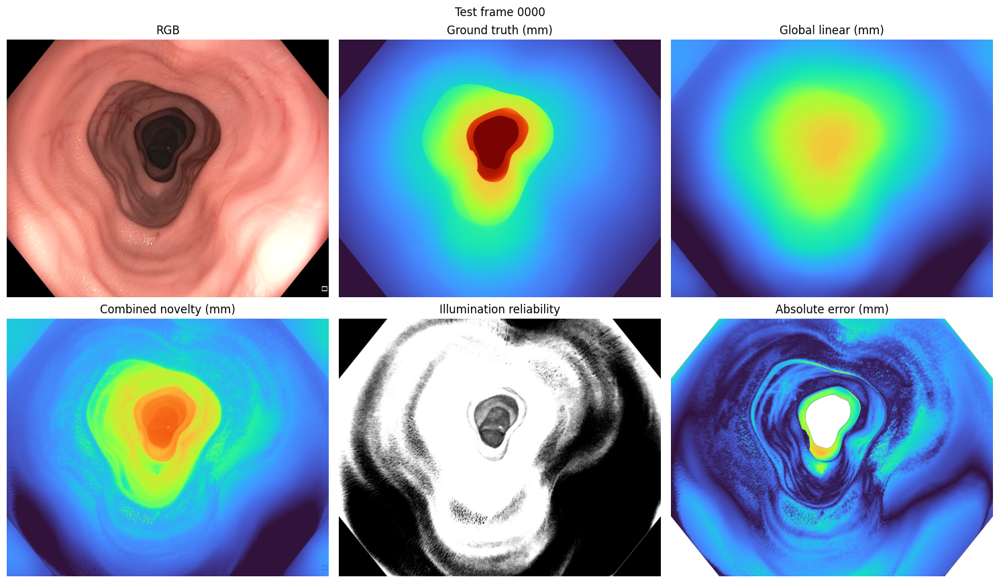

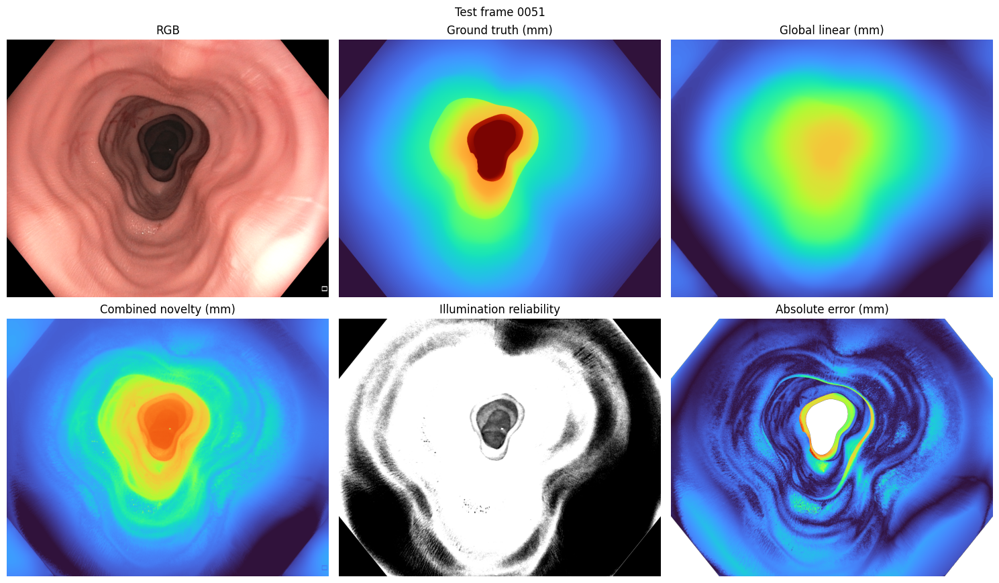

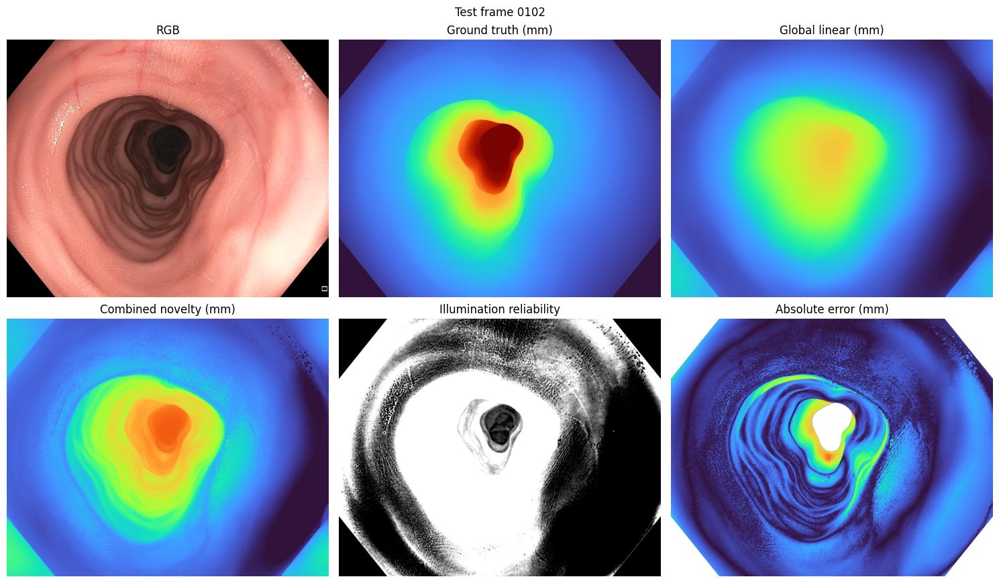

In [104]:
# Visual evidence: RGB, GT, unweighted illumination model, combined model, reliability and errors.
for k in [0,len(test_records)//2,len(test_records)-1]:
    rec=test_records[k]
    rgb,pred,gt,valid,lum,rel,spec,shadow=load_record(rec)
    plain=predict_variant(fitted['A_global_linear'],pred,lum,rel,'base')
    combined=predict_variant(fitted['D_combined_interaction'],pred,lum,rel,'combined')
    panels=[rgb,gt,plain,combined,rel,np.where(valid,np.abs(combined-gt),np.nan)]
    names=['RGB','Ground truth (mm)','Global linear (mm)','Combined novelty (mm)',
           'Illumination reliability','Absolute error (mm)']
    fig,axs=plt.subplots(2,3,figsize=(15,9))
    for ax,img,name in zip(axs.flat,panels,names):
        if name=='RGB': ax.imshow(img)
        elif name=='Illumination reliability': ax.imshow(img,cmap='gray',vmin=0,vmax=1)
        else: ax.imshow(img,cmap='turbo',vmin=0,vmax=(40 if 'error' in name.lower() else 100))
        ax.set_title(name);ax.axis('off')
    fig.suptitle('Test frame '+rec[0]);fig.tight_layout()
    fig.savefig(OUT/f'novelty_visual_{rec[0]}.png',dpi=160,bbox_inches='tight')
    plt.show()

### Interpretation and reporting checklist

- Report **all** rows, including negative results. A brightness cue can fail under the C3VD texture shift.
- This is a **regression-based post-processing calibration**, not neural-network fine-tuning. The illumination weighting is heuristic and should not be described as calibrated physical photometry.
- Report the chosen alpha, dev-block validation procedure, model checkpoint and the ground-truth TIFF decoding. The fixed `gt > 0 and gt < 100 mm` mask excludes saturated pixels.
- **Do not** compare to previous notebook tables as if protocols were identical unless the ground-truth mask, median baseline and aggregation match.
- Your earlier notebook also contains **Large** and **metric indoor/outdoor** model predictions. This extension intentionally uses **DAv2 Small** `dev_predictions` and `test_predictions` only. For MiDaS, raw MiDaS predictions must be substituted and the same pipeline rerun; it is not a MiDaS modification.
- A positive performance gain is not guaranteed. Check especially near/far depth errors and specular-region errors, and do not choose methods based on held-out test results.